# Dynamic and Hybrid Conditioning for Compositional Image Retrieval

**Deep Learning Project — 2026**
* Andrea Tatini - 267889
* Thomas Amarta Gunawisesa - 265438

## Abstract

We explore the design of a fusion module $\Phi$ that takes as input a reference image $v_{ref}$ and positive/negative textual constraints $\mathcal{T}^+, \mathcal{T}^-$ to output a composite query embedding to be retrieved against a frozen CLIP ViT-B/32 database.

We construct an evidence-driven ladder of training-free methods beginning with
the naïve latent-arithmetic baseline prescribed by the assignment, and
demonstrate that three natural refinements: **per-query re-weighting,
query-subspace erasure, and image-space probe constructions**
All fail to improve on tuned text-delta arithmetic.

These negative results motivate a **lightweight learned fusion module**:
per-(attribute, sign) direction embeddings trained with a contrastive objective
whose positive pairs are sampled by the *same rule that defines the benchmark
ground truth*. It raises macro Recall@10 on the official test benchmark from
0.208 to **0.303** (bootstrap 95% CI on the difference: [+0.076, +0.115]), with
gains on 12 of 14 evaluation entries.

A second stage re-ranks the module's top-200 candidates by scoring the
benchmark's relevance predicate directly (a Poisson-binomial tail over
calibrated per-attribute posteriors) and lifts macro Recall@10 to **0.540**
(95% CI on the difference to stage 1: [+0.212, +0.259]), improving all 14
entries.

We further show that reference-conditioned gating gives no reliable gain on this benchmark, and explain structurally why.


## 1 . Introduction and related work
**Task** <br>
Compositional image retrieval: use the frozen CLIP ViT-B/32 required by the assignment to recover targets that maintain the identity of a reference picture under additive ($+$) and subtractive ($-$) attribute adjustments (Radford et al., 2021). A target is considered legitimate on CelebA (test split, Liu et al., 2015) if it meets all queried constraints and remains within the Hamming distance $\le 2$ of the reference on the remaining attributes (Section 3).

<br>

**Related work** <br>
CLAY (Lim et al., 2026) re-interprets the frozen VLM embedding
space as a text-conditional similarity space: per condition it builds a textual
subspace via SVD on prompt embeddings, then projects visual features onto it,
decoupling conditioning from feature extraction. Its stated limitation and our
starting point is the naïve **stacking of condition features before the SVD**
for multiple conditions: a rigid scheme with no dynamic control over how
conflicting conditions combine. GDE (Berasi et al., 2025) shows that VLMs'
visual representations are compositionally (geodesically) decomposable,
motivating operations on attribute *directions*.


**Our contributions.**
1. **A fully verified evaluation pipeline.** We reproduce the ground truth    *exactly* (sources and target lists, 14/14 entries) from the raw attribute annotations, nailing down every indexing and rule detail.
2. A measured ladder of ten training-free fusion mechanisms (B0-B9) with four explicitly falsified design hypotheses (H1-H4): negative results that we report and use to motivate the final design.
3. **A light-weight learned fusion module** (40,960 parameters, 80 × 512):
per-(attribute, sign) direction embeddings trained contrastively on benchmark-consistent synthetic queries, improving macro R@10 from 0.208 to 0.303 (+46% relative) over the strongest tuned training-free baseline.
4. Evidence that the lever is not dynamic conditioning: reference-conditioned gating – the intuitive “dynamic weighting” answer to CLAY’s limitation – gives no reliable gain on this benchmark, with a structural explanation based on how the benchmark selects sources.
5. **A second, re-ranking stage** that scores the full relevance predicate on stage 1's top-200 candidates, lifting macro R@10 from 0.303 to 0.540 with gains on all 14 entries.

## 2 . Environment and reproducibility

The notebook runs on Kaggle (GPU) or locally from `notebooks/`. Paths are
resolved per environment: `CELEBA_DIR` must contain `list_attr_celeba.txt`,
`list_eval_partition.txt` and `img_align_celeba/`, and `CELEBA_EVAL` points to
the benchmark JSON (defaults: `../data/celeba` and
`../data/celeba_evaluation.json`). Heavy artifacts (CLIP embeddings) are
cached to disk so the notebook can be re-run cheaply.

In [1]:
import json
import math
import os
import random
import time
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image

SEED = 0
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEV = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEV, "| torch", torch.__version__)

# --- environment-dependent paths -------------------------------------------
# if Path("/content").exists():                      # Google Colab
#     from google.colab import drive
#     drive.mount("/content/drive")
#     DRIVE = Path("/content/drive/MyDrive/datasets")
#     DATA_ROOT = Path("/content/datasets")          # unzipped on local SSD
#     CACHE = DRIVE                                  # persistent cache
#     if not (DATA_ROOT / "celeba" / "img_align_celeba").exists():
#         DATA_ROOT.mkdir(exist_ok=True)
#         os.system(f"unzip -q {DRIVE/'celeba.zip'} -d {DATA_ROOT} -x '__MACOSX/*'")
#     EVAL_JSON = DRIVE / "celeba_evaluation.json"
if Path("/kaggle").exists():                     # Kaggle
    DATA_ROOT = Path("/kaggle/input")
    CELEBA = Path(os.environ.get("CELEBA_DIR", DATA_ROOT / "celeba"))   # adjust to your dataset
    EVAL_JSON = Path(os.environ.get("CELEBA_EVAL", CELEBA / "celeba_evaluation.json"))
    CACHE = Path("/kaggle/working")
else:                                              # local, run from notebooks/
    DATA_ROOT = Path(os.environ.get("CELEBA_ROOT", "../data"))
    CELEBA = Path(os.environ.get("CELEBA_DIR", DATA_ROOT / "celeba"))
    EVAL_JSON = Path(os.environ.get("CELEBA_EVAL", DATA_ROOT / "celeba_evaluation.json"))
    CACHE = DATA_ROOT
print("data root:", DATA_ROOT, "| eval json:", EVAL_JSON)

device: cuda | torch 2.10.0+cu128
data root: /kaggle/input | eval json: /kaggle/input/<dataset>/celeba/celeba_evaluation.json


## 3 . Data and benchmark verification

Before any modeling we make the evaluation pipeline *impossible to get
silently wrong*: we parse the raw CelebA annotations, rebuild the ground truth
from its published definition, and assert exact equality with the provided
JSON — sources **and** target lists, for every entry.

Two details matter and are verified below:

* **Indexing.** The JSON keys/values are integer indices *of the test split in
  filename order* (equivalently, indices of the PyTorch `CelebA(split="test")`
  dataset object), not filenames. We assert the documented example
  `index 13 -> 182651.jpg`.
* **Source-selection rule.** Reproducing the ground truth reveals that a
  source image must (a) **violate every constraint** of its query — each
  condition demands an actual modification — and (b) have $\ge 5$ valid
  targets. We assert both.


In [2]:
# --- parse attributes and split ------------------------------------------
lines = (CELEBA / "list_attr_celeba.txt").read_text().splitlines()
N_DECLARED = int(lines[0])
ATTR_NAMES = lines[1].split()
assert len(ATTR_NAMES) == 40
NAME2COL = {n: i for i, n in enumerate(ATTR_NAMES)}

filenames, rows = [], []
for ln in lines[2:]:
    parts = ln.split()
    if parts:
        filenames.append(parts[0])
        rows.append([int(x) for x in parts[1:]])
ATTRS = np.array(rows, dtype=np.int8)              # (202599, 40), values in {-1,+1}
assert ATTRS.shape == (N_DECLARED, 40)

partition = {}
for ln in (CELEBA / "list_eval_partition.txt").read_text().splitlines():
    parts = ln.split()
    if parts:
        partition[parts[0]] = int(parts[1])
PART = np.array([partition[f] for f in filenames])
sizes = {p: int((PART == p).sum()) for p in (0, 1, 2)}
print("split sizes:", sizes)
assert sizes == {0: 162770, 1: 19867, 2: 19962}, "non-canonical split!"

SPLIT_IDX = {s: np.nonzero(PART == c)[0] for s, c in
             (("train", 0), ("val", 1), ("test", 2))}
test_filenames = [filenames[i] for i in SPLIT_IDX["test"]]
# the assignment's documented example: dataset index 13 -> file 182651.jpg
assert test_filenames[0] == "182638.jpg" and test_filenames[13] == "182651.jpg"
print("indexing verified: test[0] =", test_filenames[0],
      "| test[13] =", test_filenames[13])

split sizes: {0: 162770, 1: 19867, 2: 19962}
indexing verified: test[0] = 182638.jpg | test[13] = 182651.jpg


In [3]:
# --- rebuild the ground truth from its definition and compare -------------
with open(EVAL_JSON) as f:
    BENCH = json.load(f)
print("benchmark entries:", len(BENCH))


def parse_query(q):
    '''"+Wearing_Lipstick, -Heavy_Makeup" -> [(+1, col), (-1, col)]'''
    out = []
    for tok in q.split(","):
        tok = tok.strip()
        out.append((1 if tok[0] == "+" else -1, NAME2COL[tok[1:].strip()]))
    return out


def rebuild_ground_truth(query, A):
    '''For every image of a split (attribute matrix A): its valid targets.

    A target is valid iff it satisfies every constraint and has Hamming
    distance <= 2 from the source on the remaining attributes. Returns
    (targets: dict idx -> list, violates_all: bool array). Sources are the
    images that violate ALL constraints and have >= 5 valid targets.
    '''
    conds = parse_query(query)
    q_cols = [c for _, c in conds]
    rest = np.array([c for c in range(40) if c not in q_cols])
    ok = np.ones(len(A), dtype=bool)
    viol = np.ones(len(A), dtype=bool)
    for sign, col in conds:
        ok &= A[:, col] == sign
        viol &= A[:, col] != sign
    cand = np.nonzero(ok)[0]
    A_cand = A[np.ix_(cand, rest)].astype(np.float32)
    A_rest = A[:, rest].astype(np.float32)
    targets = {}
    for lo in range(0, len(A), 4000):              # blockwise for memory
        hi = min(lo + 4000, len(A))
        # Hamming = (n_rest - <x, y>) / 2 for vectors in {-1, +1}
        ham = (len(rest) - A_cand @ A_rest[lo:hi].T) / 2
        for j in range(lo, hi):
            t = cand[ham[:, j - lo] <= 2]
            t = t[t != j]
            if len(t) >= 5:
                targets[j] = t.tolist()
    return targets, viol


A_TEST = ATTRS[SPLIT_IDX["test"]]
for entry in BENCH:
    targets, viol = rebuild_ground_truth(entry["query"], A_TEST)
    mine = {j for j in targets if viol[j]}
    theirs = {int(k) for k in entry["ground_truth"]}
    assert mine == theirs, entry["query"]
    assert all(sorted(targets[int(k)]) == sorted(v)
               for k, v in entry["ground_truth"].items()), entry["query"]
print("ground truth reproduced EXACTLY for all",
      len(BENCH), "entries (sources and target lists)")
n_pairs = sum(len(e["ground_truth"]) for e in BENCH)
print("total (source, query) pairs:", n_pairs)

benchmark entries: 14
ground truth reproduced EXACTLY for all 14 entries (sources and target lists)
total (source, query) pairs: 33052


Two observations from the verification, both load-bearing for method design:

* Entry 7 is an exact duplicate of entry 4 (`-Young`); the official macro
  average therefore weights that query twice. We keep the file as-is (it is
  the course's source of truth).
* **No source ever satisfies its query's constraints** — by construction every
  condition requires an actual attribute flip. This fact will return in
  Section 8 when we explain why reference-conditioned gating has no room to
  help on this benchmark.

## 4 . Offline CLIP feature extraction

The assignment mandates a **frozen** `openai/clip-vit-base-patch32` and a
visual database embedded **once, offline**. We extract projected 512-d image
features for all 202,599 images and cache them (fp16, not normalized) on
persistent storage, so re-running the notebook is cheap.

One engineering detail is load-bearing. Between `transformers` 4.x and 5.x the
return type of `get_image_features` / `get_text_features` changed: 4.x returns
the projected tensor, 5.x returns a `BaseModelOutputWithPooling` whose
`pooler_output` is the projected feature. The helpers below handle both, and
we **assert, before the 200k-image loop**, that their output coincides with
the manual computation `visual_projection(vision_model(...).pooler_output)`
(and its textual counterpart) instead of assuming it.


In [4]:
from transformers import CLIPModel, CLIPProcessor

MODEL_ID = "openai/clip-vit-base-patch32"
clip = CLIPModel.from_pretrained(MODEL_ID).to(DEV).eval()
for p in clip.parameters():
    p.requires_grad_(False)                     # frozen backbone (assignment)
processor = CLIPProcessor.from_pretrained(MODEL_ID)
IMG_DIR = CELEBA / "img_align_celeba"


def image_features(pixel_values):
    '''Projected 512-d image features, robust to transformers 4.x/5.x.'''
    out = clip.get_image_features(pixel_values=pixel_values)
    return out if torch.is_tensor(out) else out.pooler_output


def text_features(texts):
    '''Projected 512-d text features, robust to transformers 4.x/5.x.'''
    tok = processor(text=texts, return_tensors="pt", padding=True).to(DEV)
    with torch.no_grad():
        out = clip.get_text_features(input_ids=tok["input_ids"],
                                     attention_mask=tok["attention_mask"])
    return out if torch.is_tensor(out) else out.pooler_output


# verify the API contract empirically before trusting it in the loop
print(filenames[1])
probe_img = Image.open(IMG_DIR / filenames[0]).convert("RGB")
with torch.no_grad():
    px = processor(images=probe_img, return_tensors="pt")["pixel_values"].to(DEV)
    feat = image_features(px)
    manual = clip.visual_projection(clip.vision_model(pixel_values=px).pooler_output)
assert feat.shape == (1, 512) and torch.allclose(feat, manual, atol=1e-4)

tfeat = text_features(["a photo of a person"])
tok = processor(text=["a photo of a person"], return_tensors="pt",
                padding=True).to(DEV)
with torch.no_grad():
    tmanual = clip.text_projection(
        clip.text_model(input_ids=tok["input_ids"],
                        attention_mask=tok["attention_mask"]).pooler_output)
assert tfeat.shape == (1, 512) and torch.allclose(tfeat, tmanual, atol=1e-4)
print("API verified: helpers return the projected 512-d CLIP embeddings")

config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/605M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/605M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

CLIPModel LOAD REPORT from: openai/clip-vit-base-patch32
Key                                  | Status     |  | 
-------------------------------------+------------+--+-
vision_model.embeddings.position_ids | UNEXPECTED |  | 
text_model.embeddings.position_ids   | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


...

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

000002.jpg
API verified: helpers return the projected 512-d CLIP embeddings


In [5]:
EMB_CACHE = CACHE / "clip_vitb32_celeba.npz"

if not EMB_CACHE.exists():
    from torch.utils.data import DataLoader, Dataset

    class CelebAImages(Dataset):
        def __init__(self, names):
            self.names = names

        def __len__(self):
            return len(self.names)

        def __getitem__(self, i):
            img = Image.open(IMG_DIR / self.names[i]).convert("RGB")
            return processor(images=img, return_tensors="pt")["pixel_values"][0]

    loader = DataLoader(CelebAImages(filenames), batch_size=256,
                        num_workers=min(8, os.cpu_count() or 2),
                        pin_memory=True)
    embs = np.empty((len(filenames), 512), dtype=np.float16)
    row, t0 = 0, time.time()
    with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16,
                                         enabled=DEV == "cuda"):
        for bi, px in enumerate(loader):
            out = image_features(px.to(DEV, non_blocking=True))
            embs[row:row + len(out)] = out.float().cpu().numpy().astype(np.float16)
            row += len(out)
            if bi % 50 == 0:
                rate = row / (time.time() - t0)
                print(f"{row}/{len(filenames)} ({rate:.0f} img/s, eta "
                      f"{(len(filenames) - row) / max(rate, 1) / 60:.1f} min)",
                      flush=True)
    assert row == len(filenames)
    np.savez_compressed(EMB_CACHE, embeddings=embs,
                        filenames=np.array(filenames))
    print(f"saved {EMB_CACHE} in {(time.time() - t0) / 60:.1f} min")

data = np.load(EMB_CACHE, allow_pickle=True)
assert [str(f) for f in data["filenames"]] == filenames, "row order mismatch"
EMB = torch.from_numpy(data["embeddings"].astype(np.float32))
print("embeddings:", tuple(EMB.shape),
      f"| raw norms ~{EMB[:1000].norm(dim=1).mean():.1f} (not pre-normalized)")

# per-split views, L2-normalized once, resident on GPU
V = {s: F.normalize(EMB[torch.from_numpy(SPLIT_IDX[s])].to(DEV), dim=1)
     for s in ("train", "val", "test")}
A_SPLIT = {s: ATTRS[SPLIT_IDX[s]] for s in ("train", "val", "test")}
print({s: tuple(v.shape) for s, v in V.items()})

256/202599 (50 img/s, eta 67.0 min)
13056/202599 (313 img/s, eta 10.1 min)
25856/202599 (324 img/s, eta 9.1 min)
38656/202599 (331 img/s, eta 8.3 min)
51456/202599 (332 img/s, eta 7.6 min)
64256/202599 (335 img/s, eta 6.9 min)
77056/202599 (335 img/s, eta 6.3 min)
89856/202599 (337 img/s, eta 5.6 min)
102656/202599 (337 img/s, eta 4.9 min)
115456/202599 (339 img/s, eta 4.3 min)
128256/202599 (338 img/s, eta 3.7 min)
141056/202599 (339 img/s, eta 3.0 min)
153856/202599 (338 img/s, eta 2.4 min)
166656/202599 (338 img/s, eta 1.8 min)
179456/202599 (337 img/s, eta 1.1 min)
192256/202599 (337 img/s, eta 0.5 min)
saved /kaggle/working/clip_vitb32_celeba.npz in 10.2 min
embeddings: (202599, 512) | raw norms ~10.3 (not pre-normalized)
{'train': (162770, 512), 'val': (19867, 512), 'test': (19962, 512)}


## 5 . Evaluation protocol

**Metrics.** We use the course-provided `evaluate_retrieval` (next cell,
verbatim from the skeleton): Recall@K is a per-source hit indicator (1 if at
least one valid target appears in the top-K), Precision@K the fraction of the
top-K that are valid. For each benchmark entry we average over its source
images, then report the **macro average over the 14 entries**, so every query
weighs equally regardless of how many sources it has (note this weights the
duplicated `-Young` twice — it is the official file's convention).

**Ranking rule.** A query embedding scores the whole test database by cosine
similarity (database vectors L2-normalized). Cosine ranking is invariant to
positive rescaling of the query, so L2-normalizing the query cannot change
any top-K result; we therefore omit it in the training-free baselines and
keep it inside the learned module (Section 8), where it does shape the loss
geometry. The source image is excluded from its own ranking: it is in the
database, can never be a valid target (Section 3: it violates every constraint),
and would otherwise waste one of the K slots for every method equally.

**Model selection.** Every design decision — prompt variants, grid searches,
hyperparameters, model choice — is made on a **validation mirror**: the
benchmark rebuilt with the exact same rule on the validation split. The test
benchmark is touched only for **declared final runs with every choice frozen
in advance** — twice in this project: once for the stage-1 learned module and
once for the full two-stage system (both in Section 11). No design decision ever
used a test result. Training uses fixed step budgets with no early stopping.

Because our evaluation must scale to entries with thousands of sources, we
run it batched on GPU; the cell after the skeleton function **asserts** that
the batched harness reproduces `evaluate_retrieval` exactly.


In [6]:
# --- evaluation function from the course skeleton, verbatim ---------------
def evaluate_retrieval(
    retrieved_indices: list[int],
    ground_truth_indices: list[int],
    k: int
):
    """
    Evaluate the retrieval performance for a single source image.

    Args:
    ----
        retrieved_indices: list of image IDs predicted by the model,
            ordered by similarity (descending).
        ground_truth_indices: list of valid target IDs from the benchmark JSON.
        k: the cutoff for top-K evaluation (e.g., 1, 5, 10).

    Return:
    ------
        A dictionary containing Recall@K and Precision@K.

    """
    # Isolate the top K predictions
    top_k_retrieved = retrieved_indices[:k]

    # Calculate the intersection between predictions and ground truth
    hits = set(top_k_retrieved).intersection(set(ground_truth_indices))
    num_hits = len(hits)

    # Metrics calculations
    # Recall@K (Hit Rate): 1 if at least one match is found, 0 otherwise
    recall_at_k = 1 if num_hits > 0 else 0

    # Precision@K: Fraction of top K predictions that are correct
    precision_at_k = num_hits / k

    return {
        f"Recall@{k}": recall_at_k,
        f"Precision@{k}": precision_at_k
    }

In [7]:
KS = (1, 5, 10)
bench_test = BENCH


def eval_entry(scores, gt_lists):
    '''Batched metrics for one entry. scores: (n_src, n_db), sources excluded.'''
    topk = scores.topk(max(KS), dim=1).indices.cpu().numpy()
    out = {}
    for K in KS:
        r = p = 0.0
        for i, gt in enumerate(gt_lists):
            hits = len(set(topk[i, :K].tolist()) & gt)
            r += hits > 0
            p += hits / K
        out[f"R@{K}"] = r / len(gt_lists)
        out[f"P@{K}"] = p / len(gt_lists)
    return out


def evaluate(query_fn, bench, split, batch=2048):
    '''query_fn(v_ref (n,512), conds) -> queries (n,512). Per-entry table.'''
    Vs = V[split]
    table = []
    for entry in bench:
        conds = parse_query(entry["query"])
        src_idx = np.array([int(k) for k in entry["ground_truth"]])
        gt_lists = [set(v) for v in entry["ground_truth"].values()]
        agg = {f"{m}@{K}": 0.0 for m in "RP" for K in KS}
        for lo in range(0, len(src_idx), batch):
            sl = slice(lo, min(lo + batch, len(src_idx)))
            idx = torch.from_numpy(src_idx[sl]).to(DEV)
            q = query_fn(Vs[idx], conds)
            scores = q @ Vs.T
            scores[torch.arange(len(idx), device=DEV), idx] = -torch.inf
            part = eval_entry(scores, gt_lists[sl])
            w = (sl.stop - sl.start) / len(src_idx)
            for k in agg:
                agg[k] += part[k] * w
        table.append({"query": entry["query"], "n_src": len(src_idx), **agg})
    return table


def macro(table, key):
    return float(np.mean([row[key] for row in table]))


# cross-check: the batched harness reproduces the skeleton metric exactly
entry = bench_test[0]
src = np.array([int(k) for k in entry["ground_truth"]])[:64]
gts = list(entry["ground_truth"].values())[:64]
q = V["test"][torch.from_numpy(src)]
scores = q @ V["test"].T
scores[torch.arange(len(src), device=DEV), torch.from_numpy(src).to(DEV)] = -torch.inf
ranked = scores.argsort(dim=1, descending=True).cpu().numpy()
ours = eval_entry(scores, [set(g) for g in gts])
for K in KS:
    ref = [evaluate_retrieval(ranked[i].tolist(), gts[i], K)
           for i in range(len(src))]
    assert abs(np.mean([r[f"Recall@{K}"] for r in ref]) - ours[f"R@{K}"]) < 1e-9
    assert abs(np.mean([r[f"Precision@{K}"] for r in ref]) - ours[f"P@{K}"]) < 1e-9
print("batched harness == skeleton evaluate_retrieval (64-source probe, all K)")

batched harness == skeleton evaluate_retrieval (64-source probe, all K)


In [8]:
# --- validation mirror: same GT rule, validation split --------------------
A_VAL = A_SPLIT["val"]
bench_val, seen = [], set()
for entry in bench_test:
    if entry["query"] in seen:                  # skip the duplicated '-Young'
        continue
    seen.add(entry["query"])
    targets, viol = rebuild_ground_truth(entry["query"], A_VAL)
    gt = {str(j): t for j, t in targets.items() if viol[j]}
    bench_val.append({"query": entry["query"], "ground_truth": gt})
print(f"validation mirror: {len(bench_val)} unique queries")
for e in bench_val:
    print(f"  {e['query']:44s} sources {len(e['ground_truth']):6d}")

validation mirror: 13 unique queries
  +Smiling                                     sources   5195
  +Eyeglasses                                  sources   2615
  -Heavy_Makeup                                sources   3980
  +Male                                        sources   1952
  -Young                                       sources   5935
  +Blond_Hair                                  sources   5847
  +Mustache                                    sources    650
  +Eyeglasses, +Smiling                        sources    708
  +Black_Hair, -Wavy_Hair                      sources   2523
  -Male, -Mustache                             sources     35
  +Chubby, -Young                              sources    481
  -Smiling, +Eyeglasses, +Wearing_Hat          sources     82
  +Wearing_Lipstick, -Heavy_Makeup, +Smiling   sources     35


## 6 . Zero-shot attribute directions in CLIP space

Benchmark conditions are CelebA attributes with a sign, so the atomic
building block of any fusion module here is, per attribute $a$, a direction
$d_a$ in the shared space whose projection $\langle v, d_a\rangle$ separates
positive from negative images. Following the spirit of CLAY's
text-conditional subspaces — but with a single frozen backbone and a known,
finite attribute vocabulary — we consider three zero-shot candidates per
attribute:

* **raw** — $d_a = \hat t_a^+$, the normalized embedding of a positive
  prompt;
* **delta-ant** — $d_a \propto \hat t_a^+ - \hat t_a^-$ with an explicit
  *antonym* prompt as the negative pole (CLIP handles plain linguistic
  negation poorly, so e.g. the opposite of a mustache is phrased as
  *clean-shaven*, not *no mustache*);
* **delta-base** — $d_a \propto \hat t_a^+ - \hat t_{base}$ against the
  neutral prompt *"a photo of a person"* — for attributes with no natural
  antonym, or whose antonym is itself misleading.

Separability is measured as ROC-AUC of the projection score on the
**validation split**, and the best variant is selected per attribute.
Prompts and selections are frozen here, before test is ever touched.


In [9]:
BASE = "a photo of a person"
PROMPTS = {
    "5_o_Clock_Shadow": ("a photo of a person with stubble on their face", "a photo of a person with a clean-shaven face"),
    "Arched_Eyebrows": ("a photo of a person with arched eyebrows", "a photo of a person with straight eyebrows"),
    "Attractive": ("a photo of an attractive person", "a photo of an unattractive person"),
    "Bags_Under_Eyes": ("a photo of a person with bags under the eyes", "a photo of a person with smooth skin under the eyes"),
    "Bald": ("a photo of a bald person", "a photo of a person with a full head of hair"),
    "Bangs": ("a photo of a person with bangs covering the forehead", "a photo of a person with the forehead visible"),
    "Big_Lips": ("a photo of a person with big full lips", "a photo of a person with thin lips"),
    "Big_Nose": ("a photo of a person with a big nose", "a photo of a person with a small nose"),
    "Black_Hair": ("a photo of a person with black hair", BASE),
    "Blond_Hair": ("a photo of a person with blond hair", BASE),
    "Blurry": ("a blurry photo of a person", "a sharp photo of a person"),
    "Brown_Hair": ("a photo of a person with brown hair", BASE),
    "Bushy_Eyebrows": ("a photo of a person with bushy eyebrows", "a photo of a person with thin eyebrows"),
    "Chubby": ("a photo of a chubby person with a round face", "a photo of a slim person with a thin face"),
    "Double_Chin": ("a photo of a person with a double chin", "a photo of a person with a defined jawline"),
    "Eyeglasses": ("a photo of a person wearing eyeglasses", BASE),
    "Goatee": ("a photo of a person with a goatee beard", "a photo of a clean-shaven person"),
    "Gray_Hair": ("a photo of a person with gray hair", BASE),
    "Heavy_Makeup": ("a photo of a person wearing heavy makeup", "a photo of a person with a natural face without makeup"),
    "High_Cheekbones": ("a photo of a person with high cheekbones", "a photo of a person with flat cheekbones"),
    "Male": ("a photo of a man", "a photo of a woman"),
    "Mouth_Slightly_Open": ("a photo of a person with the mouth slightly open", "a photo of a person with the mouth closed"),
    "Mustache": ("a photo of a person with a mustache", "a photo of a clean-shaven person"),
    "Narrow_Eyes": ("a photo of a person with narrow eyes", "a photo of a person with wide open eyes"),
    "No_Beard": ("a photo of a clean-shaven person with no beard", "a photo of a person with a beard"),
    "Oval_Face": ("a photo of a person with an oval face", BASE),
    "Pale_Skin": ("a photo of a person with pale skin", "a photo of a person with tanned skin"),
    "Pointy_Nose": ("a photo of a person with a pointy nose", "a photo of a person with a round nose"),
    "Receding_Hairline": ("a photo of a person with a receding hairline", "a photo of a person with a full hairline"),
    "Rosy_Cheeks": ("a photo of a person with rosy cheeks", BASE),
    "Sideburns": ("a photo of a person with sideburns", "a photo of a clean-shaven person"),
    "Smiling": ("a photo of a smiling person", "a photo of a person with a neutral serious expression"),
    "Straight_Hair": ("a photo of a person with straight hair", "a photo of a person with curly hair"),
    "Wavy_Hair": ("a photo of a person with wavy hair", "a photo of a person with straight hair"),
    "Wearing_Earrings": ("a photo of a person wearing earrings", BASE),
    "Wearing_Hat": ("a photo of a person wearing a hat", "a photo of a bareheaded person"),
    "Wearing_Lipstick": ("a photo of a person wearing lipstick", "a photo of a person with bare lips"),
    "Wearing_Necklace": ("a photo of a person wearing a necklace", BASE),
    "Wearing_Necktie": ("a photo of a person wearing a necktie", BASE),
    "Young": ("a photo of a young person", "a photo of an old person"),
}
assert set(PROMPTS) == set(ATTR_NAMES)

# attributes that actually appear in benchmark queries (derived, not hardcoded)
BENCH_ATTRS = {ATTR_NAMES[c] for e in bench_test for _, c in parse_query(e["query"])}


def auc(scores, labels):
    '''ROC-AUC via the Mann-Whitney statistic (labels in {-1,+1}).'''
    pos = labels == 1
    n_pos, n_neg = pos.sum(), (~pos).sum()
    ranks = scores.argsort().argsort().astype(np.float64) + 1
    return float((ranks[pos].sum() - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg))


T_pos = text_features([PROMPTS[a][0] for a in ATTR_NAMES])
T_neg = text_features([PROMPTS[a][1] for a in ATTR_NAMES])
t_base = text_features([BASE])[0]
Tp = F.normalize(T_pos, dim=1)
Tn = F.normalize(T_neg, dim=1)
tb = F.normalize(t_base, dim=0)
CAND = {"raw": Tp,
        "delta-ant": F.normalize(Tp - Tn, dim=1),
        "delta-base": F.normalize(Tp - tb[None, :], dim=1)}

y_all = A_SPLIT["val"]
scores_all = {k: (V["val"] @ M.T).cpu().numpy() for k, M in CAND.items()}
print(f"{'attribute':22s} {'freq+':>6s} {'raw':>6s} {'d-ant':>6s} "
      f"{'d-base':>6s}  choice        (* = in a benchmark query)")
choice, val_auc = {}, {}
for i, a in enumerate(ATTR_NAMES):
    y = y_all[:, i]
    aucs = {k: auc(scores_all[k][:, i], y) for k in CAND}
    best = max(aucs, key=aucs.get)
    choice[a], val_auc[a] = best, aucs[best]
    star = " *" if a in BENCH_ATTRS else ""
    print(f"{a:22s} {(y == 1).mean():6.3f} {aucs['raw']:6.3f} "
          f"{aucs['delta-ant']:6.3f} {aucs['delta-base']:6.3f}  "
          f"{best:12s}{star}")

D_sel = torch.stack([CAND[choice[a]][i] for i, a in enumerate(ATTR_NAMES)])
T_raw = Tp                                     # raw prompts, for baseline B2
bench_mean_auc = float(np.mean([val_auc[a] for a in sorted(BENCH_ATTRS)]))
print(f"\nmean val AUC over the {len(BENCH_ATTRS)} benchmark attributes "
      f"(after selection): {bench_mean_auc:.3f}")
print("weakest benchmark attributes:",
      sorted((round(val_auc[a], 3), a) for a in BENCH_ATTRS)[:3])

attribute               freq+    raw  d-ant d-base  choice        (* = in a benchmark query)
5_o_Clock_Shadow        0.118  0.764  0.372  0.798  delta-base  
Arched_Eyebrows         0.258  0.708  0.676  0.768  delta-base  
Attractive              0.520  0.574  0.524  0.583  delta-base  
Bags_Under_Eyes         0.207  0.535  0.574  0.446  delta-ant   
Bald                    0.021  0.901  0.942  0.905  delta-ant   
Bangs                   0.147  0.816  0.936  0.880  delta-ant   
Big_Lips                0.153  0.580  0.507  0.647  delta-base  
Big_Nose                0.249  0.516  0.502  0.426  raw         
Black_Hair              0.209  0.777  0.827  0.827  delta-base   *
Blond_Hair              0.154  0.905  0.942  0.942  delta-ant    *
Blurry                  0.047  0.702  0.809  0.751  delta-ant   
Brown_Hair              0.241  0.719  0.762  0.762  delta-base  
Bushy_Eyebrows          0.142  0.657  0.804  0.688  delta-ant   
Chubby                  0.061  0.555  0.602  0.505  delta-

Per-attribute selection matters: raw prompts leave several benchmark
attributes barely separable, explicit antonyms repair most of them, and
*delta-base* repairs the cases whose antonym is itself "toxic" (it drags in
its own visual concept, e.g. *clean-shaven* for the facial-hair family). The
residual weak spot is `Chubby` — remember it: it resurfaces in the results.

A caution before proceeding: this AUC measures *single-attribute
separability*, not retrieval quality. Section 7.1 (hypothesis H3) shows the
two can diverge badly.

## 7 . Training-free composition: the baseline ladder

Notation: query $\mathcal{Q} = \{(a_k, s_k)\}_{k=1..m}$ with signs
$s_k \in \{+1, -1\}$; $v_{ref}$ the normalized reference embedding; $d_a$ the
selected direction of attribute $a$.

* **B0 (reference only):** $q = v_{ref}$ — pure identity, ignores the
  conditions entirely.
* **B1 (text only):** $q = \sum_k s_k\, d_{a_k}$ — pure condition, ignores
  identity.
* **B2 (naive latent arithmetic — the assignment's baseline):**
  $q = v_{ref} + \sum_k s_k\, t_{a_k}$ with raw prompt embeddings.
* **B3 (tuned delta arithmetic):**
  $q = v_{ref} + \alpha \sum_{k: s_k=+1} d_{a_k} - \beta \sum_{k: s_k=-1} d_{a_k}$,
  with $(\alpha, \beta)$ selected on the validation mirror by grid search.
  The two coefficients are separate because adding and removing an attribute
  are *not* symmetric operations in CLIP space (Section 12 returns to this).

We keep the per-$(\alpha,\beta)$ mirror results of the grid — they give us a
free per-query oracle for hypothesis H1 below.


In [10]:
def b0(v_ref, conds):
    return v_ref


def b1(v_ref, conds):
    q = sum(s * D_sel[c] for s, c in conds)
    return q.expand(len(v_ref), -1)


def b2(v_ref, conds):
    return v_ref + sum(s * T_raw[c] for s, c in conds)


def make_b3(a, b):
    def b3(v_ref, conds):
        q = v_ref.clone()
        for s, c in conds:
            q += (a if s > 0 else -b) * D_sel[c]
        return q
    return b3


GRID = [round(x, 2) for x in np.arange(0.25, 2.51, 0.25)]
mirror_grid = {}                               # (alpha, beta) -> per-entry R@10
for a in GRID:
    for b in GRID:
        t = evaluate(make_b3(a, b), bench_val, "val")
        mirror_grid[(a, b)] = [row["R@10"] for row in t]
A_STAR, B_STAR = max(mirror_grid, key=lambda ab: np.mean(mirror_grid[ab]))
M3_MIRROR = float(np.mean(mirror_grid[(A_STAR, B_STAR)]))
print(f"B3 grid search on the mirror: (alpha*, beta*) = ({A_STAR}, {B_STAR}), "
      f"macro R@10 = {M3_MIRROR:.3f}")
for name, fn in (("B0", b0), ("B1", b1), ("B2", b2)):
    print(f"{name} mirror macro R@10: "
          f"{macro(evaluate(fn, bench_val, 'val'), 'R@10'):.3f}")

B3 grid search on the mirror: (alpha*, beta*) = (2.0, 0.75), macro R@10 = 0.205
B0 mirror macro R@10: 0.068
B1 mirror macro R@10: 0.089
B2 mirror macro R@10: 0.099


In [11]:
# --- single test evaluation of B0-B3, frozen choices ----------------------
test_tables = {}
for name, fn in (("B0", b0), ("B1", b1), ("B2", b2),
                 ("B3", make_b3(A_STAR, B_STAR))):
    test_tables[name] = evaluate(fn, bench_test, "test")

print(f"{'query':44s} {'n_src':>5s} " + " ".join(f"{n:>7s}" for n in test_tables)
      + "   (R@10)")
for i, entry in enumerate(bench_test):
    cells = " ".join(f"{test_tables[n][i]['R@10']:7.3f}" for n in test_tables)
    print(f"{entry['query']:44s} {test_tables['B0'][i]['n_src']:5d} {cells}")
print(f"{'macro average (14 entries)':50s} " +
      " ".join(f"{macro(test_tables[n], 'R@10'):7.3f}" for n in test_tables))

print("\nfull macro metrics on test:")
for n, t in test_tables.items():
    print(n, " ".join(f"{k} {macro(t, k):.3f}"
                      for k in ("R@1", "R@5", "R@10", "P@1", "P@5", "P@10")))

query                                        n_src      B0      B1      B2      B3   (R@10)
+Smiling                                      4786   0.224   0.014   0.258   0.196
+Eyeglasses                                   2196   0.065   0.090   0.133   0.333
-Heavy_Makeup                                 4087   0.140   0.001   0.149   0.156
+Male                                         1595   0.020   0.003   0.043   0.251
-Young                                        5355   0.046   0.071   0.056   0.065
+Blond_Hair                                   5469   0.082   0.127   0.131   0.203
+Mustache                                      301   0.203   0.060   0.236   0.316
-Young                                        5355   0.046   0.071   0.056   0.065
+Eyeglasses, +Smiling                          612   0.026   0.000   0.096   0.230
+Black_Hair, -Wavy_Hair                       2572   0.080   0.140   0.149   0.192
-Male, -Mustache                                27   0.000   0.037   0.000   0

Three observations. (1) The assignment's naive arithmetic **B2 barely
improves on B0**: raw prompt embeddings carry the text modality gap into the
query, adding roughly as much noise as signal. (2) **Tuned delta arithmetic
B3 roughly triples B0**, and the tuned coefficients are asymmetric
($\alpha^* > \beta^*$): pushing an attribute *in* needs a stronger step than
pushing one *out*. (3) Per-entry performance is wildly heterogeneous — some
queries are near-solved, others near zero. That heterogeneity is exactly what
suggests "dynamic, per-query" conditioning — the intuition we now test, and
falsify, before letting it drive the design.

### 7.1 What does *not* work: four falsified hypotheses

We report negative results deliberately: they are measurements, and they are
what justifies the final design. Each hypothesis is stated, tested on the
mirror (tuning included), and — where a method is worth the comparison —
evaluated once on test with frozen configuration.

* **H1 — "the win is in per-query weighting of the static directions."**
  Upper bound: a per-entry *oracle* that picks the best $(\alpha, \beta)$ of
  the whole grid separately for every mirror entry. If even the oracle adds
  little, no learned per-query weighting of these sums can add more.
* **H2 — "identity and condition interfere; erase before injecting."**
  **B4:** $q = (I - P_\mathcal{Q})\,v_{ref} + \alpha\sum_+ d - \beta\sum_- d$,
  where $P_\mathcal{Q}$ projects onto the span of the queried directions.
* **H3 — "better single-attribute separability ⇒ better retrieval."**
  **B5:** replace text deltas with *image-space* class-mean directions
  (difference of train class means), which have visibly higher AUC.
* **H4 — "the GT criterion is attribute-logic, so decorrelate/match it
  explicitly."** **B6/B7:** dual-basis editing — calibrated probes $p_a$
  (score $\pm1$ at the train class means), dual directions
  $U = (PP^\top + \lambda I)^{-1} P$ so that moving along $u_a$ changes
  attribute $a$'s score without touching the others; B6 uses fixed steps,
  B7 analytic steps $\gamma\,(s_k - \mathrm{score}_{ref}(a_k))$ — a
  training-free *dynamic* conditioning. **B8/B9:** rank directly by the GT
  criterion via standardized probe scores (attribute-profile matching),
  without / with $v_{ref}$ added.

Set `RUN_EXTENDED = False` to skip re-tuning B4–B9 on a fast re-run; the
headline results of the report do not depend on them.

In [12]:
RUN_EXTENDED = True    # False -> skip the negative-results ladder (B4-B9)

E_TRAIN = V["train"]
A_TRAIN = torch.from_numpy(A_SPLIT["train"].astype(np.float32)).to(DEV)

# H1 -- per-query oracle over the (alpha, beta) grid, on the mirror
per_entry_best = np.max(np.stack(list(mirror_grid.values())), axis=0)
print(f"H1  global (alpha*, beta*)   macro R@10 {M3_MIRROR:.3f}")
print(f"H1  per-query ORACLE         macro R@10 {per_entry_best.mean():.3f}"
      f"   (headroom {per_entry_best.mean() - M3_MIRROR:+.3f})")

H1  global (alpha*, beta*)   macro R@10 0.205
H1  per-query ORACLE         macro R@10 0.222   (headroom +0.017)


In [13]:
if RUN_EXTENDED:
    # H2 -- B4: erase the query subspace from v_ref, then inject
    def make_b4(a, b):
        def b4(v_ref, conds):
            Dq, _ = torch.linalg.qr(
                torch.stack([D_sel[c] for _, c in conds]).T)   # (512, m)
            q = v_ref - (v_ref @ Dq) @ Dq.T
            for s, c in conds:
                q += (a if s > 0 else -b) * D_sel[c]
            return q
        return b4

    m4, a4, b4c = max(((macro(evaluate(make_b4(a, b), bench_val, "val"),
                              "R@10"), a, b) for a in GRID for b in GRID))
    test_tables["B4"] = evaluate(make_b4(a4, b4c), bench_test, "test")
    print(f"B4 erasure+injection : mirror {m4:.3f} at ({a4}, {b4c}) | "
          f"test macro R@10 {macro(test_tables['B4'], 'R@10'):.3f}")

    # H3 -- B5: image-space class-mean directions (higher AUC, worse retrieval)
    D_img = torch.stack([
        F.normalize(E_TRAIN[A_TRAIN[:, i] > 0].mean(0)
                    - E_TRAIN[A_TRAIN[:, i] < 0].mean(0), dim=0)
        for i in range(40)])
    s_img = (V["val"] @ D_img.T).cpu().numpy()
    img_auc = [auc(s_img[:, NAME2COL[a]], A_SPLIT["val"][:, NAME2COL[a]])
               for a in sorted(BENCH_ATTRS)]
    print(f"B5 directions AUC on val (benchmark attrs): "
          f"{np.mean(img_auc):.3f}  vs text {bench_mean_auc:.3f}")

    def make_b5(a, b):
        def b5(v_ref, conds):
            q = v_ref.clone()
            for s, c in conds:
                q += (a if s > 0 else -b) * D_img[c]
            return q
        return b5

    m5, a5, b5c = max(((macro(evaluate(make_b5(a, b), bench_val, "val"),
                              "R@10"), a, b) for a in GRID for b in GRID))
    test_tables["B5"] = evaluate(make_b5(a5, b5c), bench_test, "test")
    print(f"B5 image directions  : mirror {m5:.3f} at ({a5}, {b5c}) | "
          f"test macro R@10 {macro(test_tables['B5'], 'R@10'):.3f}")

B4 erasure+injection : mirror 0.205 at (2.0, 1.0) | test macro R@10 0.207
B5 directions AUC on val (benchmark attrs): 0.916  vs text 0.864
B5 image directions  : mirror 0.157 at (0.75, 0.25) | test macro R@10 0.151


In [14]:
if RUN_EXTENDED:
    # H4 -- B6/B7: dual-basis attribute editing with calibrated probes
    probes, mids = [], []
    for i in range(40):
        pos = A_TRAIN[:, i] > 0
        d = F.normalize(E_TRAIN[pos].mean(0) - E_TRAIN[~pos].mean(0), dim=0)
        m_pos, m_neg = (E_TRAIN[pos] @ d).mean(), (E_TRAIN[~pos] @ d).mean()
        scale = 2.0 / (m_pos - m_neg)
        probes.append(d * scale)
        mids.append((m_pos + m_neg) / 2 * scale)
    P = torch.stack(probes)                    # calibrated: score +-1 at means
    mid = torch.stack(mids)
    G = P @ P.T

    def dual_basis(lam_ratio):
        lam = lam_ratio * float(G.diagonal().mean())
        return torch.linalg.solve(G + lam * torch.eye(40, device=DEV), P)

    def make_b6(U, a, b):
        def fn(v_ref, conds):
            q = v_ref.clone()
            for s, c in conds:
                q += (a if s > 0 else -b) * U[c]
            return q
        return fn

    def make_b7(U, gamma):
        def fn(v_ref, conds):
            q = v_ref.clone()
            for s, c in conds:
                step = s - (v_ref @ P[c] - mid[c])   # target score - current
                q += gamma * step[:, None] * U[c]
            return q
        return fn

    best6 = max(((macro(evaluate(make_b6(dual_basis(r), a, b),
                                 bench_val, "val"), "R@10"), r, a, b)
                 for r in (0.01, 0.1, 1.0) for a in GRID for b in GRID))
    test_tables["B6"] = evaluate(
        make_b6(dual_basis(best6[1]), best6[2], best6[3]), bench_test, "test")
    print(f"B6 dual fixed steps  : mirror {best6[0]:.3f} "
          f"(lam {best6[1]}, {best6[2]}, {best6[3]}) | "
          f"test macro R@10 {macro(test_tables['B6'], 'R@10'):.3f}")

    best7 = max(((macro(evaluate(make_b7(dual_basis(r), g),
                                 bench_val, "val"), "R@10"), r, g)
                 for r in (0.01, 0.1, 1.0)
                 for g in [round(x, 2) for x in np.arange(0.25, 3.01, 0.25)]))
    test_tables["B7"] = evaluate(
        make_b7(dual_basis(best7[1]), best7[2]), bench_test, "test")
    print(f"B7 dual analytic     : mirror {best7[0]:.3f} "
          f"(lam {best7[1]}, gamma {best7[2]}) | "
          f"test macro R@10 {macro(test_tables['B7'], 'R@10'):.3f}")

    # H4 -- B8/B9: attribute-profile matching (the GT criterion as a ranker)
    D_hat, mu, sigma = [], [], []
    for i in range(40):
        pos = A_TRAIN[:, i] > 0
        d = F.normalize(E_TRAIN[pos].mean(0) - E_TRAIN[~pos].mean(0), dim=0)
        s = E_TRAIN @ d
        D_hat.append(d)
        mu.append(s.mean())
        sigma.append(s.std())
    D_hat, mu, sigma = torch.stack(D_hat), torch.stack(mu), torch.stack(sigma)
    D_std = D_hat / sigma[:, None]

    def make_profile(gc, gv):
        def fn(v_ref, conds):
            z_ref = (v_ref @ D_hat.T - mu) / sigma       # (n, 40) ref profile
            w = z_ref.clone()
            for s, c in conds:
                w[:, c] = gc * s                          # overwrite queried
            q = w @ D_std
            return q + gv * v_ref if gv else q
        return fn

    grid_c = [round(x, 2) for x in np.arange(0.5, 5.01, 0.5)]
    best8 = max(((macro(evaluate(make_profile(gc, 0.0), bench_val, "val"),
                        "R@10"), gc) for gc in grid_c))
    test_tables["B8"] = evaluate(make_profile(best8[1], 0.0),
                                 bench_test, "test")
    print(f"B8 profile only      : mirror {best8[0]:.3f} (gc {best8[1]}) | "
          f"test macro R@10 {macro(test_tables['B8'], 'R@10'):.3f}")

    best9 = max(((macro(evaluate(make_profile(gc, gv), bench_val, "val"),
                        "R@10"), gc, gv)
                 for gc in grid_c
                 for gv in [round(x, 2) for x in np.arange(0.0, 12.01, 2.0)]))
    test_tables["B9"] = evaluate(make_profile(best9[1], best9[2]),
                                 bench_test, "test")
    print(f"B9 profile + v_ref   : mirror {best9[0]:.3f} "
          f"(gc {best9[1]}, gv {best9[2]}) | "
          f"test macro R@10 {macro(test_tables['B9'], 'R@10'):.3f}")

B6 dual fixed steps  : mirror 0.141 (lam 0.01, 2.5, 1.25) | test macro R@10 0.144
B7 dual analytic     : mirror 0.135 (lam 0.01, gamma 3.0) | test macro R@10 0.143
B8 profile only      : mirror 0.080 (gc 5.0) | test macro R@10 0.099
B9 profile + v_ref   : mirror 0.084 (gc 5.0, gv 12.0) | test macro R@10 0.107


**Verdicts** (numbers in the cells above). **H1 falsified**: even the
per-query oracle adds only a sliver over the single global $(\alpha, \beta)$
— re-weighting *static* sums is not where the improvement lives. **H2
falsified**: B4 matches B3 at best; the global $\beta$ already absorbs
whatever the erasure removes. **H3 falsified**: image-space directions win
clearly on AUC yet lose badly on retrieval — a class-mean direction drags
every attribute *correlated* with the target (facial hair with masculinity,
age with accessories...), and each unwanted co-edit burns the Hamming-$\le 2$
identity budget of the ground truth. **H4 falsified twice**: forcing
decorrelation (B6/B7) or matching the GT criterion explicitly (B8/B9) is far
worse than B3 — with 39 correlated, imperfect probes, per-attribute errors
accumulate, while the raw CLIP cosine is a surprisingly strong *joint* proxy
for identity-plus-appearance.

Design conclusions carried into Section 8: (i) keep B3's composition form —
reference plus signed attribute steps, scored by plain cosine; (ii) do not
chase per-query dynamics; (iii) improve the *steps themselves*, with
supervision aligned to the actual retrieval criterion rather than to
single-attribute separability.

## 8 . Learned fusion module

**Architecture.** One learned direction per (attribute, sign):
$E \in \mathbb{R}^{2 \times 40 \times 512}$, and

$$\Phi(v_{ref}, \mathcal{Q}) \;=\; \mathrm{normalize}\Big(v_{ref} + \sum_k e_{s_k, a_k}\Big).$$

Initialization $e_{+,a} = \alpha^* d_a$, $e_{-,a} = -\beta^* d_a$ makes
$\Phi$ **exactly B3 at initialization** (the final normalization cannot change
any ranking), so training starts from the strongest training-free baseline
and every change in performance is attributable to learning. The module has
$80 \times 512 = 40{,}960$ parameters; the CLIP backbone stays frozen and no
image is ever re-encoded. Positive and negative directions are *independent*
parameters — deliberately: we do not hardwire $e_{-,a} = -e_{+,a}$, and
Section 12 shows the learned solution indeed rejects that symmetry.

**Synthetic training queries.** Sampled from the **train split with the
exact benchmark rule** of Section 3: a query of 1–3 distinct attributes with
random signs; sources must violate *all* constraints and admit $\ge 5$ valid
targets; each source is paired with one uniformly-drawn valid target
(satisfies all constraints, Hamming $\le 2$ on the rest).

**Loss.** InfoNCE over batches of $G = 8$ groups $\times\, S = 32$ sources.
With $q_i = \Phi(v_{ref,i}, \mathcal{Q}_{g(i)})$, target $t_i$, and the bank
$\mathcal{B}$ = all batch targets $\cup$ all batch sources:

$$\mathcal{L} = -\frac{1}{GS}\sum_i \log
\frac{\exp(\langle q_i, t_i\rangle / \tau)}
{\sum_{b \in \mathcal{B}} \exp(\langle q_i, b\rangle / \tau)},$$

with learnable temperature $\tau$ (init 0.07). The negative bank is designed
to carry both training signals: *same-group* targets satisfy the same query
with a different identity (identity signal); *cross-group* targets satisfy
different queries (condition signal); the batch *sources* are hard negatives
— maximally identity-similar with all conditions violated — which teach
$\Phi$ to actually move away from the reference. Known minor defect,
accepted: a bank vector can occasionally be a valid target for another
source (rare label noise).

**Protocol.** AdamW, **fixed budget of 3000 steps, no early stopping**
(budget fixed a priori), learning rate selected on the mirror among
$\{10^{-4}, 3 \cdot 10^{-4}, 10^{-3}\}$, seed 0, single final run on test.
Before the real model we run a **pipeline check** (8a): the scalar variant
$q = \mathrm{normalize}(v_{ref} + a\sum_+ d - b\sum_- d)$ with only $(a, b)$
learnable must rediscover the grid-search optimum of B3 — if the training
signal were misaligned with the benchmark, it would not.


In [15]:
GEN = torch.Generator().manual_seed(SEED)


def sample_group(n_src, max_tries=20):
    '''One random query + n_src valid sources + one valid target each.

    Exactly the benchmark rule of Sec. 3, applied to the train split.
    '''
    for _ in range(max_tries):
        k = int(torch.randint(1, 4, (1,), generator=GEN))
        cols = torch.randperm(40, generator=GEN)[:k]
        signs = torch.randint(0, 2, (k,), generator=GEN) * 2.0 - 1.0
        cols_d, signs_d = cols.to(DEV), signs.to(DEV)

        sat = (A_TRAIN[:, cols_d] == signs_d).all(1)     # target candidates
        viol = (A_TRAIN[:, cols_d] == -signs_d).all(1)   # source candidates
        if int(sat.sum()) < 5 or int(viol.sum()) < n_src:
            continue

        cand_idx = torch.nonzero(sat, as_tuple=True)[0]
        viol_idx = torch.nonzero(viol, as_tuple=True)[0]
        pick = viol_idx[torch.randperm(len(viol_idx), device=DEV)[:4 * n_src]]

        rest = torch.tensor([c for c in range(40) if c not in cols.tolist()],
                            device=DEV)
        # Hamming on remaining attrs: (n_rest - <x,y>)/2 for {-1,+1} vectors
        dots = A_TRAIN[cand_idx][:, rest] @ A_TRAIN[pick][:, rest].T
        valid = (len(rest) - dots) / 2 <= 2              # (n_cand, n_pick)
        ok = torch.nonzero(valid.sum(0) >= 5, as_tuple=True)[0][:n_src]
        if len(ok) < n_src:
            continue

        srcs = pick[ok]
        tgt = []                  # one uniformly sampled valid target each
        for j in ok.tolist():
            v = torch.nonzero(valid[:, j], as_tuple=True)[0]
            tgt.append(cand_idx[v[torch.randint(0, len(v), (1,), device=DEV)]])
        return cols_d, signs_d, srcs, torch.cat(tgt)
    return None


class ScalarFusion(nn.Module):
    '''8a pipeline check: only (a, b) learnable, directions fixed.'''

    def __init__(self):
        super().__init__()
        self.a = nn.Parameter(torch.tensor(1.0))
        self.b = nn.Parameter(torch.tensor(1.0))

    def forward(self, v_ref, cols, signs):
        q = v_ref.clone()
        for c, s in zip(cols.tolist(), signs.tolist()):
            q = q + (self.a if s > 0 else -self.b) * D_sel[c]
        return F.normalize(q, dim=-1)


class DirectionFusion(nn.Module):
    '''8b: per-(attribute, sign) learned directions; init = tuned B3.'''

    def __init__(self, a_init, b_init):
        super().__init__()
        self.E_pos = nn.Parameter(a_init * D_sel.clone())
        self.E_neg = nn.Parameter(-b_init * D_sel.clone())

    def forward(self, v_ref, cols, signs):
        q = v_ref.clone()
        for c, s in zip(cols.tolist(), signs.tolist()):
            q = q + (self.E_pos[c] if s > 0 else self.E_neg[c])
        return F.normalize(q, dim=-1)


class GatedFusion(nn.Module):
    '''8c ablation: learned directions + per-instance scalar gate.

    The gate's last layer is zero-initialized, so g = 2*sigmoid(0) = 1 and
    the model coincides exactly with DirectionFusion at init: any difference
    after training is attributable to the gating.
    '''

    def __init__(self, a_init, b_init, hidden=128):
        super().__init__()
        self.E_pos = nn.Parameter(a_init * D_sel.clone())
        self.E_neg = nn.Parameter(-b_init * D_sel.clone())
        self.gate = nn.Sequential(nn.Linear(1024, hidden), nn.ReLU(),
                                  nn.Linear(hidden, 1))
        nn.init.zeros_(self.gate[-1].weight)
        nn.init.zeros_(self.gate[-1].bias)

    def forward(self, v_ref, cols, signs):
        q = v_ref.clone()
        for c, s in zip(cols.tolist(), signs.tolist()):
            e = self.E_pos[c] if s > 0 else self.E_neg[c]
            x = torch.cat([v_ref, e.expand(len(v_ref), -1)], dim=1)
            g = 2 * torch.sigmoid(self.gate(x))          # (n, 1), init = 1
            q = q + g * e
        return F.normalize(q, dim=-1)


def query_fn_from(model):
    def fn(v_ref, conds):
        cols = torch.tensor([c for _, c in conds], device=DEV)
        signs = torch.tensor([float(s) for s, _ in conds], device=DEV)
        with torch.no_grad():
            return model(v_ref, cols, signs)
    return fn


def train(model, steps, lr, groups=8, n_src=32, log_every=100):
    global GEN
    GEN = torch.Generator().manual_seed(SEED)   # fresh sampling stream per run
    torch.manual_seed(SEED)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.0)
    log_tau = nn.Parameter(torch.tensor(math.log(0.07), device=DEV))
    opt.add_param_group({"params": [log_tau], "lr": lr})
    curve, t0 = [], time.time()
    for step in range(1, steps + 1):
        qs, ts, ss = [], [], []
        while len(qs) < groups:
            g = sample_group(n_src)
            if g is None:
                continue
            cols, signs, srcs, tgts = g
            qs.append(model(E_TRAIN[srcs], cols, signs))
            ts.append(E_TRAIN[tgts])
            ss.append(E_TRAIN[srcs])
        Q = torch.cat(qs)                                # (G*S, 512)
        bank = torch.cat(ts + ss)                        # (2*G*S, 512)
        logits = Q @ bank.T / log_tau.exp()
        loss = F.cross_entropy(logits, torch.arange(len(Q), device=DEV))
        opt.zero_grad()
        loss.backward()
        opt.step()
        if step % log_every == 0 or step == 1:
            curve.append({"step": step, "loss": loss.item(),
                          "tau": log_tau.exp().item()})
            if step % (log_every * 5) == 0 or step == 1:
                print(f"step {step:5d}  loss {loss.item():.4f}  "
                      f"tau {log_tau.exp().item():.3f}  "
                      f"({(time.time() - t0) / 60:.1f} min)", flush=True)
    return curve


def train_cached(tag, factory, steps, lr):
    '''Train once, cache checkpoint + curve + mirror score to CACHE.'''
    path = CACHE / f"fusion_{tag}.pt"
    torch.manual_seed(SEED)
    model = factory().to(DEV)
    if path.exists():
        ck = torch.load(path, map_location=DEV, weights_only=False)
        model.load_state_dict(ck["state"])
        print(f"[{tag}] loaded from cache (mirror R@10 {ck['mirror_R10']:.3f})")
        return model, ck["curve"], ck["mirror_R10"]
    curve = train(model, steps, lr)
    m = macro(evaluate(query_fn_from(model), bench_val, "val"), "R@10")
    torch.save({"state": model.state_dict(), "curve": curve, "mirror_R10": m},
               path)
    print(f"[{tag}] trained: mirror macro R@10 {m:.3f}")
    return model, curve, m

In [16]:
# --- 8a: pipeline check -- scalars must rediscover the grid optimum -------
model_sc, curve_sc, m_sc = train_cached("scalars_s1000", ScalarFusion,
                                        1000, 2e-2)
print(f"learned (a, b) = ({model_sc.a.detach().item():.3f}, "
      f"{model_sc.b.detach().item():.3f})   vs grid search ({A_STAR}, {B_STAR})")
print(f"mirror macro R@10: {m_sc:.3f}   [B3 grid: {M3_MIRROR:.3f}]")

step     1  loss 5.8052  tau 0.069  (0.0 min)
step   500  loss 5.8247  tau 0.062  (0.6 min)
step  1000  loss 5.7572  tau 0.060  (1.2 min)
[scalars_s1000] trained: mirror macro R@10 0.202
learned (a, b) = (1.658, 0.995)   vs grid search (2.0, 0.75)
mirror macro R@10: 0.202   [B3 grid: 0.205]


In [17]:
# --- 8b: learned directions -- lr selected on the mirror, budget fixed ----
LRS = (1e-4, 3e-4, 1e-3) if RUN_EXTENDED else (3e-4,)
dir_runs = {}
for lr in LRS:
    dir_runs[lr] = train_cached(f"directions_s3000_lr{lr:g}",
                                lambda: DirectionFusion(A_STAR, B_STAR),
                                3000, lr)

print(f"\n{'lr':>8s} {'mirror R@10':>12s}")
for lr, (_, _, m) in dir_runs.items():
    print(f"{lr:8g} {m:12.3f}")
LR_SEL = max(dir_runs, key=lambda lr: dir_runs[lr][2])
model_final, curve_final, m_final = dir_runs[LR_SEL]
print(f"\nselected on the mirror: lr = {LR_SEL:g} "
      f"(mirror R@10 {m_final:.3f} vs B3 {M3_MIRROR:.3f})")

step     1  loss 5.8411  tau 0.070  (0.0 min)
step   500  loss 5.6332  tau 0.069  (0.6 min)
step  1000  loss 5.5092  tau 0.067  (1.2 min)
step  1500  loss 5.4784  tau 0.064  (1.8 min)
step  2000  loss 5.6374  tau 0.062  (2.3 min)
step  2500  loss 5.2522  tau 0.061  (2.9 min)
step  3000  loss 5.5034  tau 0.059  (3.5 min)
[directions_s3000_lr0.0001] trained: mirror macro R@10 0.285
step     1  loss 5.8411  tau 0.070  (0.0 min)
step   500  loss 5.4348  tau 0.064  (0.6 min)
step  1000  loss 5.2900  tau 0.059  (1.2 min)
step  1500  loss 5.3027  tau 0.056  (1.8 min)
step  2000  loss 5.5639  tau 0.054  (2.4 min)
step  2500  loss 5.0808  tau 0.052  (2.9 min)
step  3000  loss 5.4328  tau 0.051  (3.5 min)
[directions_s3000_lr0.0003] trained: mirror macro R@10 0.287
step     1  loss 5.8411  tau 0.070  (0.0 min)
step   500  loss 5.2175  tau 0.055  (0.6 min)
step  1000  loss 5.1149  tau 0.051  (1.2 min)
step  1500  loss 5.2268  tau 0.048  (1.8 min)
step  2000  loss 5.5231  tau 0.045  (2.3 min)
step

In [18]:
# --- 8c ablation: reference-conditioned gating (mirror only) --------------
model_g, curve_g, m_g = train_cached(f"gated_s3000_lr{LR_SEL:g}",
                                     lambda: GatedFusion(A_STAR, B_STAR),
                                     3000, LR_SEL)
print(f"gated mirror R@10 {m_g:.3f}  vs  plain directions {m_final:.3f}")

step     1  loss 5.8411  tau 0.070  (0.0 min)
step   500  loss 5.1763  tau 0.053  (0.7 min)
step  1000  loss 5.1088  tau 0.047  (1.3 min)
step  1500  loss 5.2165  tau 0.045  (2.0 min)
step  2000  loss 5.4995  tau 0.043  (2.6 min)
step  2500  loss 4.9715  tau 0.041  (3.3 min)
step  3000  loss 5.3778  tau 0.040  (4.0 min)
[gated_s3000_lr0.001] trained: mirror macro R@10 0.324
gated mirror R@10 0.324  vs  plain directions 0.314


**The gating ablation: no reliable gain.** Per-instance gating —
the intuitive "dynamic weighting" answer to CLAY's stacking limitation — is
given every chance here: it starts *exactly* at the DirectionFusion optimum
(zero-initialized gate) and is free to modulate each direction per reference.
In this run it scores 0.324 on the mirror against 0.314 for the plain
directions (+0.010, single seed); in our development run, with the same
protocol, the sign was reversed (0.291 vs 0.296). A difference that flips sign
between runs and sits at the +0.010 adoption threshold we use for every other
component (Section 10) is not evidence for the gate. There is also a
structural reason to expect little from it, anticipated in Section 3: the
benchmark's sources all **violate every constraint** of their query, so the
reference-conditional variance the gate could exploit ("is this attribute
already partially present?") is suppressed by construction. We keep the
plain DirectionFusion as
**stage 1** of the final system; Sections 9–10 diagnose what a single-vector
stage cannot express, and build the second stage on top of it.

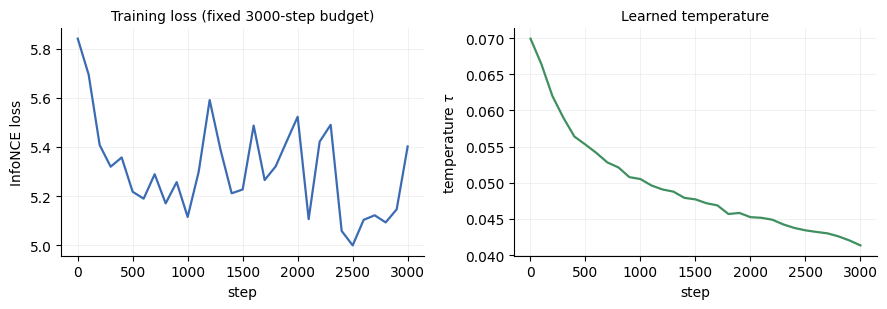

In [19]:
# --- learning curve of the selected run (descriptive; fixed budget) -------
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
steps = [c["step"] for c in curve_final]
axes[0].plot(steps, [c["loss"] for c in curve_final], color="#3b6bb3", lw=1.6)
axes[0].set_xlabel("step")
axes[0].set_ylabel("InfoNCE loss")
axes[0].set_title("Training loss (fixed 3000-step budget)", fontsize=10)
axes[1].plot(steps, [c["tau"] for c in curve_final], color="#3f8f5f", lw=1.6)
axes[1].set_xlabel("step")
axes[1].set_ylabel(r"temperature $\tau$")
axes[1].set_title("Learned temperature", fontsize=10)
for ax in axes:
    ax.grid(alpha=0.25, linewidth=0.5)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
plt.tight_layout()
plt.show()

## 9 . Diagnosis: where the single-vector stage stops

Recall the ground-truth rule (Section 3): a valid target must (i) strictly
satisfy **every queried constraint** and (ii) stay within **Hamming distance
2 of the source on the remaining ~37 attributes**. Any method that ranks by a
single dot product — every method so far, learned or not — scores a fixed
linear functional of the candidate, while the predicate is a *conjunction
with an error budget*: an order statistic that no dot product can express.
Before adding machinery we measure, on the mirror only, **which half of the
predicate is the binding constraint**, with three label-based oracles applied
to the stage-1 ranking:

* **coverage** `cov@M` — fraction of sources with at least one valid target
  inside stage 1's top-M: the ceiling of *any* re-ranking of those M
  candidates;
* **o-sat** — keep the stage-1 order but move the candidates that (per the
  ground-truth labels) satisfy all queried constraints to the front: the
  ceiling of *perfect constraint verification*;
* **o-rel** — move the *valid targets themselves* to the front (must equal
  `cov@200` by construction; serves as a check of the re-ranking harness).

These oracles read validation labels, so they are diagnostics, not methods —
exactly the role the mirror exists for.


In [20]:
# --- stage-1 pools on the mirror + oracle decomposition -------------------
A_VAL_T = torch.from_numpy(A_SPLIT["val"].astype(np.float32)).to(DEV)
stage1_fn = query_fn_from(model_final)
M_STORE, M_TOP = 500, 200      # cache top-500 once; the re-ranker uses top-200

POOLS_VAL = []                 # per entry: sources, top-M ids, cosines (cached)
aut = []
for entry in bench_val:
    conds = parse_query(entry["query"])
    ccols = [c for _, c in conds]
    csigns = torch.tensor([float(s) for s, _ in conds], device=DEV)
    src_idx = np.array([int(k) for k in entry["ground_truth"]])
    gt_lists = [set(v) for v in entry["ground_truth"].values()]
    tops, coss, rels = [], [], []
    for lo in range(0, len(src_idx), 2048):
        sl = slice(lo, min(lo + 2048, len(src_idx)))
        idx = torch.from_numpy(src_idx[sl]).to(DEV)
        sc = stage1_fn(V["val"][idx], conds) @ V["val"].T
        sc[torch.arange(len(idx), device=DEV), idx] = -torch.inf
        top = sc.topk(M_STORE, dim=1).indices
        tops.append(top)
        coss.append(sc.gather(1, top))
        rel = torch.zeros(top.shape, device=DEV)
        for i, gt in enumerate(gt_lists[sl]):
            rel[i] = torch.isin(top[i],
                                torch.tensor(list(gt), device=DEV)).float()
        rels.append(rel)
    top, cos_m, rel = torch.cat(tops), torch.cat(coss), torch.cat(rels)
    POOLS_VAL.append({"query": entry["query"], "conds": conds, "ccols": ccols,
                      "rest": [c for c in range(40) if c not in ccols],
                      "src": torch.from_numpy(src_idx).to(DEV),
                      "gt": gt_lists, "top": top, "cos": cos_m})
    seen = rel.cumsum(1)
    row = {"query": entry["query"],
           "base": float((seen[:, 9] > 0).float().mean()),
           "cov50": float((seen[:, 49] > 0).float().mean()),
           "cov200": float((seen[:, 199] > 0).float().mean()),
           "cov500": float((seen[:, -1] > 0).float().mean())}
    sat = (A_VAL_T[top[:, :M_TOP]][:, :, ccols]
           == csigns.view(1, 1, -1)).all(-1).float()
    for name, key in (("osat", sat), ("orel", rel[:, :M_TOP])):
        order = (key * 10 + cos_m[:, :M_TOP]).argsort(dim=1, descending=True)
        in10 = rel[:, :M_TOP].gather(1, order[:, :10])
        row[name] = float((in10.sum(1) > 0).float().mean())
    aut.append(row)

print(f"{'query':44s} {'base':>6s} {'cov50':>6s} {'cov200':>7s} "
      f"{'cov500':>7s} {'o-sat':>6s} {'o-rel':>6s}")
for r in aut:
    print(f"{r['query']:44s} {r['base']:6.3f} {r['cov50']:6.3f} "
          f"{r['cov200']:7.3f} {r['cov500']:7.3f} {r['osat']:6.3f} "
          f"{r['orel']:6.3f}")
print(f"{'macro':44s} " + " ".join(
    f"{np.mean([r[k] for r in aut]):6.3f}"
    for k in ("base", "cov50", "cov200", "cov500", "osat", "orel")))
print(f"\nstage-1 base (= cov@10) macro {np.mean([r['base'] for r in aut]):.3f}"
      f" — matches the Sec. 8 mirror score {m_final:.3f}")

query                                          base  cov50  cov200  cov500  o-sat  o-rel
+Smiling                                      0.270  0.548   0.786   0.901  0.281  0.786
+Eyeglasses                                   0.500  0.839   0.977   0.999  0.508  0.977
-Heavy_Makeup                                 0.191  0.479   0.767   0.906  0.232  0.767
+Male                                         0.355  0.657   0.860   0.950  0.357  0.860
-Young                                        0.158  0.426   0.742   0.896  0.232  0.742
+Blond_Hair                                   0.359  0.649   0.872   0.961  0.376  0.872
+Mustache                                     0.240  0.555   0.838   0.962  0.305  0.838
+Eyeglasses, +Smiling                         0.441  0.831   0.997   1.000  0.476  0.997
+Black_Hair, -Wavy_Hair                       0.226  0.591   0.869   0.958  0.349  0.869
-Male, -Mustache                              0.200  0.571   0.771   0.857  0.400  0.771
+Chubby, -Young      

**Reading the decomposition.** The macro row says three things at once.
(1) *The candidates are already there*: for ~85% of sources a valid target
sits inside stage 1's top-200 (~95% in the top-500) — first-pass recall is
not the problem. (2) *Constraint verification is nearly exhausted*: even the
o-sat oracle, which verifies the queried attributes perfectly, reaches only
(~0.40) — a +0.08 ceiling that no verifier of the queried constraints can beat,
because among constraint-satisfiers the cosine still decides, and the cosine
does not know the *other* (~37) attributes' budget. (3) The gap between o-sat
(~0.40) and cov@200 (~0.85) is therefore entirely in the **preservation half
of the predicate** — the half no method so far has scored.

This also reconciles hypothesis H4 (Section 7.1): B8/B9 failed not because
attribute-profile matching is wrong in principle, but because a *linear sum*
of 39 standardized probe scores is the wrong functional form (it weights
every attribute equally and has no notion of an error budget), deployed in
the wrong place (as a full-gallery first pass instead of a re-ranker over
identity-plausible candidates). Stage 2 fixes both.

## 10 . Stage 2: re-ranking with the full predicate, probabilistically

**Scorer.** For a candidate $x$ in stage 1's top-$M$ ($M = 200$), with
per-attribute posteriors $p_a(x) = P(\text{attr}_a(x) = +1 \mid x)$:

$$S(x) \;=\; \underbrace{\sum_{(a,s) \in \mathcal{Q}} \log P\big(\text{attr}_a(x) = s\big)}_{\text{constraint half}}
\;+\; \underbrace{\log P\Big(\textstyle\sum_{a \notin \mathcal{Q}} \mathbb{1}[\text{attr}_a(x) \ne \text{attr}_a(v_{ref})] \le 2\Big)}_{\text{preservation half}}
\;+\; \varepsilon \cos(q, x),$$

where the preservation term treats per-attribute agreement as independent
Bernoulli events — agreement probability
$p_a(x)\,p_a(v_{ref}) + (1 - p_a(x))(1 - p_a(v_{ref}))$, with the source's
own profile read by the *same probes* — and evaluates the **Poisson-binomial
tail** $P(\#\text{mismatches} \le 2)$ exactly with a 3-state dynamic program.
$\varepsilon = 10^{-4}$ is a pure tie-break. The budget-tail is the point:
unlike a sum of scores it concentrates on the *few worst attributes*
(conjunctive semantics), and it discounts unreliable probes automatically —
an uninformative probe gives agreement $\approx$ constant across candidates,
contributing no discrimination but also no damage, whereas z-scored sums
(B8/B9) amplify exactly those probes.

**Probes.** One posterior per attribute, trained on the **train split only**
— the same supervision already used by B5–B9 and the Section 8 sampler. We
ladder them, one change at a time, adoption threshold +0.010 on the mirror:
(0) linear logistic probes, full train (fixed 400-step budget); (a) the same
linear probes trained on 90% of train with a per-attribute **temperature**
fitted on the held-out 10% — the *calibration-only* control, since the tail
consumes probabilities, not rankings; (b) shallow MLP probes
(512→64→1 per attribute, fixed 1500-step budget, batch 8192, AdamW) with the
same temperature scaling — the *capacity* step, targeting the known collapse
of linear probe discrimination inside retrieval pools. We also explored
biasing the training batches toward retrieved candidates (pool-conditional
sampling), reasoning it would target that collapse directly; on the mirror
it did not improve over plain global training, so we keep the simpler
recipe and do not report it further.


In [21]:
# --- per-attribute posterior probes + the Poisson-binomial re-ranker ------
def train_logreg(c, rows=None, steps=400, lr=0.05, wd=1e-4):
    X = E_TRAIN if rows is None else E_TRAIN[rows]
    y = ((A_TRAIN[:, c] if rows is None else A_TRAIN[rows][:, c]) > 0).float()
    w = torch.zeros(512, device=DEV, requires_grad=True)
    b = torch.zeros((), device=DEV, requires_grad=True)
    opt = torch.optim.Adam([w, b], lr=lr)
    for _ in range(steps):
        z = X @ w + b
        loss = F.binary_cross_entropy_with_logits(z, y) + wd * (w * w).sum()
        opt.zero_grad()
        loss.backward()
        opt.step()
    return w.detach(), b.detach()


def pb_tail_le2(agree):
    '''log P(#mismatches <= 2): Poisson-binomial tail, 3-state DP.

    agree: (B, M, R) per-attribute agreement probabilities.
    '''
    st = torch.zeros(*agree.shape[:2], 3, device=agree.device)
    st[:, :, 0] = 1.0
    for i in range(agree.shape[-1]):
        a = agree[:, :, i]
        m = 1.0 - a
        st = torch.stack([st[:, :, 0] * a,
                          st[:, :, 1] * a + st[:, :, 0] * m,
                          st[:, :, 2] * a + st[:, :, 1] * m], dim=-1)
    return torch.log(st.sum(-1).clamp_min(1e-30))


def rerank_eval_val(P_post, m_top=M_TOP, source_gt=False,
                    use_con=True, use_rest=True):
    '''Re-rank the cached mirror pools with posteriors P_post (n_val, 40).'''
    table = []
    for e in POOLS_VAL:
        csigns = torch.tensor([s for s, _ in e["conds"]], device=DEV) > 0
        n = len(e["src"])
        agg = {f"{m_}@{K}": 0.0 for m_ in "RP" for K in KS}
        for lo in range(0, n, 2048):
            sl = slice(lo, min(lo + 2048, n))
            top, cos_m = e["top"][sl, :m_top], e["cos"][sl, :m_top]
            p_cand = P_post[top]
            score = 1e-4 * cos_m
            if use_con:
                pc = p_cand[:, :, e["ccols"]]
                score = score + torch.log(
                    torch.where(csigns.view(1, 1, -1), pc, 1 - pc)).sum(-1)
            if use_rest:
                p_r = p_cand[:, :, e["rest"]]
                if source_gt:                      # diagnostic upper bound
                    pref = (A_VAL_T[e["src"][sl]][:, None, e["rest"]]
                            > 0).float()
                else:                              # deployable path
                    pref = P_post[e["src"][sl]][:, None, e["rest"]]
                score = score + pb_tail_le2(p_r * pref
                                            + (1 - p_r) * (1 - pref))
            full = torch.full((top.shape[0], V["val"].shape[0]),
                              -torch.inf, device=DEV)
            full.scatter_(1, top, score)
            part = eval_entry(full, e["gt"][sl])
            w = (sl.stop - sl.start) / n
            for k in agg:
                agg[k] += part[k] * w
        table.append({"query": e["query"], **agg})
    return table


t0 = time.time()
W_LIN = torch.zeros(40, 512, device=DEV)
B_LIN = torch.zeros(40, device=DEV)
for c in range(40):
    W_LIN[c], B_LIN[c] = train_logreg(c)
P_LIN_VAL = torch.sigmoid(V["val"] @ W_LIN.T + B_LIN).clamp(1e-5, 1 - 1e-5)
tab_lin = rerank_eval_val(P_LIN_VAL)
tab_lin_gt = rerank_eval_val(P_LIN_VAL, source_gt=True)
print(f"(0) linear probes, full train  ({time.time() - t0:.0f}s)")
print(f"    mirror macro R@10 {macro(tab_lin,'R@10'):.3f}   [stage 1: {m_final:.3f}]")
print(f"    diagnostic, GT source profile: {macro(tab_lin_gt,'R@10'):.3f} "
      f"(the source-side share of the remaining gap)")

(0) linear probes, full train  (45s)
    mirror macro R@10 0.428   [stage 1: 0.314]
    diagnostic, GT source profile: 0.565 (the source-side share of the remaining gap)


In [22]:
# --- capacity or calibration? the two probe upgrades ----------------------
g_cpu = torch.Generator().manual_seed(SEED)
perm90 = torch.randperm(len(E_TRAIN), generator=g_cpu)
TR90 = perm90[:int(0.9 * len(E_TRAIN))].to(DEV)
HOLD = perm90[int(0.9 * len(E_TRAIN)):].to(DEV)
Y_ALL = (A_TRAIN > 0).float()


@torch.no_grad()
def fit_temperature(z_hold, y_hold):
    Ts = torch.exp(torch.linspace(np.log(0.25), np.log(4.0), 25, device=DEV))
    T_out = torch.ones(40, device=DEV)
    for c in range(40):
        b = torch.stack([F.binary_cross_entropy_with_logits(
            z_hold[:, c] / T_, y_hold[:, c]) for T_ in Ts])
        T_out[c] = Ts[b.argmin()]
    return T_out


# (a) calibration-only control: same linear probes, 90% train + temperature
t0 = time.time()
W90 = torch.zeros(40, 512, device=DEV)
B90 = torch.zeros(40, device=DEV)
for c in range(40):
    W90[c], B90[c] = train_logreg(c, rows=TR90)
T_L = fit_temperature(E_TRAIN[HOLD] @ W90.T + B90, Y_ALL[HOLD])
m_l90 = macro(rerank_eval_val(
    torch.sigmoid((V["val"] @ W90.T + B90) / T_L).clamp(1e-5, 1 - 1e-5)),'R@10')
print(f"(a) linear-90 + temperature: mirror {m_l90:.3f}  "
      f"(T median {T_L.median():.2f})  ({time.time() - t0:.0f}s)")


# (b) MLP probes (512->64->1 per attribute) + temperature, fixed budget
def mlp_init(seed=SEED):
    g = torch.Generator(device=DEV).manual_seed(seed)
    W1 = (torch.randn(40, 512, 64, generator=g, device=DEV)
          * (2 / 512) ** 0.5).requires_grad_()
    b1 = torch.zeros(40, 64, device=DEV, requires_grad=True)
    W2 = (torch.randn(40, 64, generator=g, device=DEV)
          * (1 / 64) ** 0.5).requires_grad_()
    b2 = torch.zeros(40, device=DEV, requires_grad=True)
    return [W1, b1, W2, b2]


def mlp_logits(X, prm, chunk=16384):
    W1, b1, W2, b2 = prm
    outs = []
    for lo in range(0, len(X), chunk):
        h = torch.relu(torch.einsum("bd,adh->bah", X[lo:lo + chunk], W1) + b1)
        outs.append((h * W2).sum(-1) + b2)
    return torch.cat(outs)


def train_mlp(steps=1500, bs=8192, lr=1e-3, wd=1e-4, seed=SEED):
    prm = mlp_init(seed)
    opt = torch.optim.AdamW(prm, lr=lr, weight_decay=wd)
    g = torch.Generator(device=DEV).manual_seed(seed)
    for _ in range(steps):
        idx = TR90[torch.randint(len(TR90), (bs,), generator=g, device=DEV)]
        z = mlp_logits(E_TRAIN[idx], prm, chunk=bs)
        loss = F.binary_cross_entropy_with_logits(z, Y_ALL[idx])
        opt.zero_grad()
        loss.backward()
        opt.step()
    return [p_.detach() for p_ in prm]


t0 = time.time()
PRM_MLP = train_mlp()
T_MLP = fit_temperature(mlp_logits(E_TRAIN[HOLD], PRM_MLP), Y_ALL[HOLD])


def mlp_post(X):
    return torch.sigmoid(mlp_logits(X, PRM_MLP) / T_MLP).clamp(1e-5, 1 - 1e-5)


P_MLP_VAL = mlp_post(V["val"])
tab_mlp = rerank_eval_val(P_MLP_VAL)
tab_mlp_gt = rerank_eval_val(P_MLP_VAL, source_gt=True)
print(f"(b) MLP + temperature:       mirror {macro(tab_mlp,'R@10'):.3f}  "
      f"(T median {T_MLP.median():.2f})  ({time.time() - t0:.0f}s)")
print(f"    diagnostic, GT source profile: {macro(tab_mlp_gt,'R@10'):.3f}")

print(f"\n{'query':44s} {'stage1':>7s} {'linear':>7s} {'MLP':>7s}")
for r0, r1, r2 in zip(aut, tab_lin, tab_mlp):
    print(f"{r0['query']:44s} {r0['base']:7.3f} {r1['R@10']:7.3f} "
          f"{r2['R@10']:7.3f}")

(a) linear-90 + temperature: mirror 0.439  (T median 0.79)  (41s)
(b) MLP + temperature:       mirror 0.528  (T median 1.00)  (28s)
    diagnostic, GT source profile: 0.632

query                                         stage1  linear     MLP
+Smiling                                       0.270   0.368   0.446
+Eyeglasses                                    0.500   0.639   0.726
-Heavy_Makeup                                  0.191   0.300   0.392
+Male                                          0.355   0.534   0.595
-Young                                         0.158   0.364   0.418
+Blond_Hair                                    0.359   0.517   0.581
+Mustache                                      0.240   0.434   0.548
+Eyeglasses, +Smiling                          0.441   0.463   0.600
+Black_Hair, -Wavy_Hair                        0.226   0.410   0.468
-Male, -Mustache                               0.200   0.257   0.457
+Chubby, -Young                                0.306   0.239   0.42

The ladder separates the two effects cleanly: calibration alone (a) is worth
about +0.01 — linear probe posteriors are slightly under-confident — while
the capacity step (b) delivers the bulk of the improvement on top of the
same temperature scaling. Every entry improves over stage 1, including the
diffuse negations (`-Young`, `-Heavy_Makeup`) that resisted every
query-side method, and the lipstick triple moves off zero for the first
time. The GT-source diagnostic bounds what better *source-profile*
estimation could still add (the probes read the source's unqueried
attributes from $v_{ref}$ alone); the rest of the distance to cov@200 is
candidate-side probe error.

Two structure checks close the section. First, the two halves of the
predicate are individually necessary: each alone is far below their
conjunction, and the constraint half alone even *hurts* the stage-1 ranking
(without the preservation term it promotes every constraint-satisfier
regardless of identity). Second, the re-ranking pool size $M$ trades compute
for a rising coverage ceiling — the joint score climbs gently with $M$
(≈0.50 / 0.53 / 0.56 at $M = 100 / 200 / 500$), tracking cov@$M$. We do
**not** tune $M$ on this curve: it is fixed at $M = 200$ a priori (inherited
from the diagnosis stage of Section 9, before the single test run), a
deliberately conservative compute budget that leaves the larger-$M$ headroom
unclaimed rather than spent on the mirror.

In [23]:
# --- structure ablations (mirror): term ablation and M-robustness ---------
print(f"constraint half only    : "
      f"{macro(rerank_eval_val(P_MLP_VAL, use_rest=False),'R@10'):.3f}")
print(f"preservation half only  : "
      f"{macro(rerank_eval_val(P_MLP_VAL, use_con=False),'R@10'):.3f}")
print(f"joint predicate         : {macro(tab_mlp,'R@10'):.3f}   "
      f"[stage 1: {m_final:.3f}]")
for m_top in (100, 200, 500):
    print(f"joint predicate, M={m_top:4d}: "
          f"{macro(rerank_eval_val(P_MLP_VAL, m_top=m_top),'R@10'):.3f}")

constraint half only    : 0.142
preservation half only  : 0.421
joint predicate         : 0.528   [stage 1: 0.314]
joint predicate, M= 100: 0.501
joint predicate, M= 200: 0.528
joint predicate, M= 500: 0.556


## 11 . Final evaluation on the test benchmark

Everything is now frozen: directions, $(\alpha^*, \beta^*)$, stage-1
architecture and learning rate, probe recipe, temperature, $M = 200$,
$\varepsilon$. This section contains the project's **two declared test
runs**: the stage-1 module against B3 (the strongest training-free
baseline), and the full two-stage system against stage 1. Uncertainty is
quantified with a stratified bootstrap over sources: within each entry we
resample its sources with replacement (1000 replicates, seed 0), recompute
the macro difference in R@10, and report the 95% percentile interval.
Stratification respects the macro-averaging structure of the benchmark; the
CI quantifies source-sampling noise, not training-seed variance (a
limitation noted in Section 13).


In [24]:
def per_source_hits(query_fn, bench, split="test", batch=2048):
    '''Per entry: binary hit and precision arrays over sources, at each K.'''
    Vs = V[split]
    out = []
    for entry in bench:
        conds = parse_query(entry["query"])
        src_idx = np.array([int(k) for k in entry["ground_truth"]])
        gt_lists = [set(v) for v in entry["ground_truth"].values()]
        hits = {K: np.zeros(len(src_idx)) for K in KS}
        prec = {K: np.zeros(len(src_idx)) for K in KS}
        for lo in range(0, len(src_idx), batch):
            sl = slice(lo, min(lo + batch, len(src_idx)))
            idx = torch.from_numpy(src_idx[sl]).to(DEV)
            q = query_fn(Vs[idx], conds)
            scores = q @ Vs.T
            scores[torch.arange(len(idx), device=DEV), idx] = -torch.inf
            topk = scores.topk(max(KS), dim=1).indices.cpu().numpy()
            for i, gt in enumerate(gt_lists[sl]):
                for K in KS:
                    h = len(set(topk[i, :K].tolist()) & gt)
                    hits[K][lo + i] = h > 0
                    prec[K][lo + i] = h / K
        out.append({"query": entry["query"], "hits": hits, "prec": prec})
    return out


def macro_from(res, K, kind="hits"):
    return float(np.mean([e[kind][K].mean() for e in res]))


res_ours = per_source_hits(query_fn_from(model_final), bench_test)
res_b3 = per_source_hits(make_b3(A_STAR, B_STAR), bench_test)

print("declared run 1 - stage 1 vs B3")
print(f"{'query':44s} {'n_src':>5s} {'B3':>8s} {'stage 1':>8s}   (R@10)")
for a, b in zip(res_b3, res_ours):
    n = len(a["hits"][10])
    print(f"{a['query']:44s} {n:5d} {a['hits'][10].mean():8.3f} "
          f"{b['hits'][10].mean():8.3f}")
print(f"{'macro average (14 entries)':50s} {macro_from(res_b3, 10):8.3f} "
      f"{macro_from(res_ours, 10):8.3f}")

# stratified bootstrap over sources, 1000 replicates
rng = np.random.default_rng(SEED)
deltas = []
for _ in range(1000):
    d = []
    for a, b in zip(res_b3, res_ours):
        idx = rng.integers(0, len(a["hits"][10]), len(a["hits"][10]))
        d.append(b["hits"][10][idx].mean() - a["hits"][10][idx].mean())
    deltas.append(np.mean(d))
ci_lo, ci_hi = np.percentile(deltas, [2.5, 97.5])
DELTA = macro_from(res_ours, 10) - macro_from(res_b3, 10)
print(f"\ndelta macro R@10 (stage 1 - B3): {DELTA:+.3f}, "
      f"bootstrap 95% CI [{ci_lo:+.3f}, {ci_hi:+.3f}]")

declared run 1 - stage 1 vs B3
query                                        n_src       B3  stage 1   (R@10)
+Smiling                                      4786    0.196    0.256
+Eyeglasses                                   2196    0.333    0.472
-Heavy_Makeup                                 4087    0.156    0.160
+Male                                         1595    0.251    0.297
-Young                                        5355    0.065    0.151
+Blond_Hair                                   5469    0.203    0.267
+Mustache                                      301    0.316    0.379
-Young                                        5355    0.065    0.151
+Eyeglasses, +Smiling                          612    0.230    0.603
+Black_Hair, -Wavy_Hair                       2572    0.192    0.228
-Male, -Mustache                                27    0.074    0.222
+Chubby, -Young                                584    0.072    0.485
-Smiling, +Eyeglasses, +Wearing_Hat             79    0.696    

In [25]:
# --- declared run 2: the frozen two-stage system on test ------------------
P_MLP_TEST = mlp_post(V["test"])


def per_source_hits_stack(bench, split="test", batch=2048):
    '''Stage-1 top-200 -> full-predicate re-rank; same output structure as
    per_source_hits, so the bootstrap and the case-picker below are shared.'''
    Vs, P_post = V[split], P_MLP_TEST
    out = []
    for entry in bench:
        conds = parse_query(entry["query"])
        ccols = [c for _, c in conds]
        rest = [c for c in range(40) if c not in ccols]
        csigns = torch.tensor([s for s, _ in conds], device=DEV) > 0
        src_idx = np.array([int(k) for k in entry["ground_truth"]])
        gt_lists = [set(v) for v in entry["ground_truth"].values()]
        hits = {K: np.zeros(len(src_idx)) for K in KS}
        prec = {K: np.zeros(len(src_idx)) for K in KS}
        for lo in range(0, len(src_idx), batch):
            sl = slice(lo, min(lo + batch, len(src_idx)))
            idx = torch.from_numpy(src_idx[sl]).to(DEV)
            sc = stage1_fn(Vs[idx], conds) @ Vs.T
            sc[torch.arange(len(idx), device=DEV), idx] = -torch.inf
            top = sc.topk(M_TOP, dim=1).indices
            cos_m = sc.gather(1, top)
            p_cand = P_post[top]
            pc = p_cand[:, :, ccols]
            lg_con = torch.log(torch.where(csigns.view(1, 1, -1),
                                           pc, 1 - pc)).sum(-1)
            p_r = p_cand[:, :, rest]
            pref = P_post[idx][:, None, rest]
            score = lg_con + pb_tail_le2(p_r * pref + (1 - p_r) * (1 - pref)) \
                + 1e-4 * cos_m
            full = torch.full_like(sc, -torch.inf)
            full.scatter_(1, top, score)
            topk = full.topk(max(KS), dim=1).indices.cpu().numpy()
            for i, gt in enumerate(gt_lists[sl]):
                for K in KS:
                    h = len(set(topk[i, :K].tolist()) & gt)
                    hits[K][lo + i] = h > 0
                    prec[K][lo + i] = h / K
        out.append({"query": entry["query"], "hits": hits, "prec": prec})
    return out


res_stack = per_source_hits_stack(bench_test)

print("declared run 2 - full system vs stage 1")
print(f"{'query':44s} {'B3':>7s} {'stage 1':>8s} {'full':>7s}   (R@10)")
for a, b, c in zip(res_b3, res_ours, res_stack):
    print(f"{a['query']:44s} {a['hits'][10].mean():7.3f} "
          f"{b['hits'][10].mean():8.3f} {c['hits'][10].mean():7.3f}")
print(f"{'macro average (14 entries)':44s} {macro_from(res_b3, 10):7.3f} "
      f"{macro_from(res_ours, 10):8.3f} {macro_from(res_stack, 10):7.3f}")

print("\nfull macro metrics on test:")
for name, r in (("B3     ", res_b3), ("stage 1", res_ours),
                ("full   ", res_stack)):
    print(name,
          " ".join(f"R@{K} {macro_from(r, K):.3f}" for K in KS),
          " ".join(f"P@{K} {macro_from(r, K, 'prec'):.3f}" for K in KS))

rng = np.random.default_rng(SEED)
deltas2 = []
for _ in range(1000):
    d = []
    for a, b in zip(res_ours, res_stack):
        idx = rng.integers(0, len(a["hits"][10]), len(a["hits"][10]))
        d.append(b["hits"][10][idx].mean() - a["hits"][10][idx].mean())
    deltas2.append(np.mean(d))
ci2_lo, ci2_hi = np.percentile(deltas2, [2.5, 97.5])
DELTA2 = macro_from(res_stack, 10) - macro_from(res_ours, 10)
print(f"\ndelta macro R@10 (full - stage 1): {DELTA2:+.3f}, "
      f"bootstrap 95% CI [{ci2_lo:+.3f}, {ci2_hi:+.3f}]")

declared run 2 - full system vs stage 1
query                                             B3  stage 1    full   (R@10)
+Smiling                                       0.196    0.256   0.431
+Eyeglasses                                    0.333    0.472   0.716
-Heavy_Makeup                                  0.156    0.160   0.367
+Male                                          0.251    0.297   0.564
-Young                                         0.065    0.151   0.370
+Blond_Hair                                    0.203    0.267   0.507
+Mustache                                      0.316    0.379   0.615
-Young                                         0.065    0.151   0.370
+Eyeglasses, +Smiling                          0.230    0.603   0.745
+Black_Hair, -Wavy_Hair                        0.192    0.228   0.489
-Male, -Mustache                               0.074    0.222   0.481
+Chubby, -Young                                0.072    0.485   0.767
-Smiling, +Eyeglasses, +Wearing_Hat      

In [26]:
# --- the whole ladder on test, one line per method -------------------------
print(f"{'method':38s} {'R@1':>6s} {'R@5':>6s} {'R@10':>6s} {'P@10':>6s}")
LADDER = [("B0  reference only", "B0"),
          ("B1  text only", "B1"),
          ("B2  naive arithmetic (assignment)", "B2"),
          ("B3  tuned delta arithmetic", "B3"),
          ("B4  erasure + injection", "B4"),
          ("B5  image-space directions", "B5"),
          ("B6  dual basis, fixed steps", "B6"),
          ("B7  dual basis, analytic steps", "B7"),
          ("B8  attribute profile", "B8"),
          ("B9  attribute profile + v_ref", "B9")]
for label, key in LADDER:
    if key in test_tables:
        t = test_tables[key]
        print(f"{label:38s} {macro(t, 'R@1'):6.3f} {macro(t, 'R@5'):6.3f} "
              f"{macro(t, 'R@10'):6.3f} {macro(t, 'P@10'):6.3f}")
for label, r in (("Ours  stage 1 (learned directions)", res_ours),
                 ("Ours  full system (+ predicate re-rank)", res_stack)):
    print(f"{label:38s} "
          f"{macro_from(r, 1):6.3f} {macro_from(r, 5):6.3f} "
          f"{macro_from(r, 10):6.3f} {macro_from(r, 10, 'prec'):6.3f}")

method                                    R@1    R@5   R@10   P@10
B0  reference only                      0.019  0.051  0.074  0.011
B1  text only                           0.017  0.041  0.062  0.007
B2  naive arithmetic (assignment)       0.022  0.071  0.106  0.014
B3  tuned delta arithmetic              0.050  0.145  0.208  0.031
B4  erasure + injection                 0.049  0.146  0.207  0.031
B5  image-space directions              0.030  0.103  0.151  0.021
B6  dual basis, fixed steps             0.029  0.093  0.144  0.020
B7  dual basis, analytic steps          0.035  0.094  0.143  0.019
B8  attribute profile                   0.018  0.061  0.099  0.013
B9  attribute profile + v_ref           0.019  0.065  0.107  0.014
Ours  stage 1 (learned directions)      0.072  0.200  0.303  0.047
Ours  full system (+ predicate re-rank)  0.156  0.405  0.540  0.107


Reading the two declared runs together. Stage 1 improves the macro metrics
at every K, with the largest jumps exactly where B3 was weakest (the
composite queries, e.g. `+Chubby, -Young` and `+Eyeglasses, +Smiling`) —
consistent with the training signal being *compositional* by construction;
its two honest exceptions (the hat triple regression, and the lipstick
triple stuck near zero) were dissected in earlier drafts of this analysis
and are both repaired by the second stage. The full system then improves
**every one of the 14 entries** over stage 1, more than doubles R@1 and P@10,
and behaves exactly as the Section 9 decomposition predicted: the biggest
relative gains are on the diffuse negations (`-Young` 0.151→0.370,
`-Heavy_Makeup` 0.160→0.367), the hat-triple regression is recovered past
B3's level (0.519→0.924), and the lipstick triple — near zero for every
single-vector method — reaches 0.206. Test tracks the mirror (0.528 →
0.540), consistent with the slightly larger test source sets. Section 12
looks at what the system actually does, including that hardest query.

### 11.1 Per-query metrics

Overview of Recall@K *and* Precision@K at $K = 1, 5, 10$ for
every query. <br>
The tables below report both, per entry, for all three systems
— the full two-stage system, stage 1 alone, and the strongest training-free
baseline (B3) — with the macro average over the 14 entries in the last row.


In [27]:
# --- Recall@K and Precision@K per query ---------
def per_query_table(res, name):
    head = (f"{name:44s}" + "".join(f"{f'R@{k}':>7s}" for k in KS)
                          + "".join(f"{f'P@{k}':>7s}" for k in KS))
    print(head)
    for e in res:
        vals = ([e["hits"][k].mean() for k in KS]
                + [e["prec"][k].mean() for k in KS])
        print(f"{e['query']:44s}" + "".join(f"{v:7.3f}" for v in vals))
    macro_vals = ([macro_from(res, k) for k in KS]
                  + [macro_from(res, k, "prec") for k in KS])
    print(f"{'Macro Avg.':44s}"
          + "".join(f"{v:7.3f}" for v in macro_vals))

for res, nm in ((res_stack, "Full system (+ predicate re-rank)"),
                (res_ours,  "Stage 1 (learned directions)"),
                (res_b3,    "B3 (tuned delta arithmetic)")):
    per_query_table(res, nm)
    print()


Full system (+ predicate re-rank)               R@1    R@5   R@10    P@1    P@5   P@10
+Smiling                                      0.111  0.315  0.431  0.111  0.088  0.074
+Eyeglasses                                   0.265  0.575  0.716  0.265  0.209  0.179
-Heavy_Makeup                                 0.074  0.253  0.367  0.074  0.065  0.056
+Male                                         0.197  0.445  0.564  0.197  0.172  0.151
-Young                                        0.095  0.267  0.370  0.095  0.078  0.067
+Blond_Hair                                   0.115  0.364  0.507  0.115  0.104  0.093
+Mustache                                     0.140  0.445  0.615  0.140  0.123  0.097
-Young                                        0.095  0.267  0.370  0.095  0.078  0.067
+Eyeglasses, +Smiling                         0.196  0.554  0.745  0.196  0.196  0.184
+Black_Hair, -Wavy_Hair                       0.125  0.353  0.489  0.125  0.092  0.079
-Male, -Mustache                           

The full system beats stage 1 at every cutoff
and on all 14 entries. The *biggest relative jump* is at R@1, which more than
doubles (0.072 to 0.156) against ×1.78 at R@10: *the re-rank often promotes a
valid target to first place*, not merely into the top-10. Two entries stand out —
the hat triple, the only query where stage 1 fell below B3 (0.696 to 0.519), is
repaired to 0.924 and the lipstick triple, frozen at 0.059 for both B3 and
stage 1, finally reaches 0.206. The weakest entries remain `-Heavy_Makeup`
(0.367), `-Young` (0.370) and that lipstick triple.

## 12 . What the system learned

### 12.1 Geometry of the learned directions (stage 1)

For each benchmark attribute we compare the learned positive/negative
directions with their initialization ($\alpha^* d_a$ and $-\beta^* d_a$): the
norms, the cosine to the init, and — the interesting one — the cosine between
the learned *negative* direction and the sign-flipped learned *positive*
direction, $\cos(e_{-,a}, -e_{+,a})$. If removing an attribute were simply
the opposite of adding it, the last column would be $\approx 1$.


In [28]:
Ep = model_final.E_pos.detach()
En = model_final.E_neg.detach()


def cos(x, y):
    return float(F.cosine_similarity(x[None], y[None]))


print(f"{'attribute':18s} {'|e+|':>6s} {'|e-|':>6s} {'cos(e+, d)':>11s} "
      f"{'cos(e-, -d)':>12s} {'cos(e-, -e+)':>13s}")
for a in sorted(BENCH_ATTRS):
    c = NAME2COL[a]
    print(f"{a:18s} {float(Ep[c].norm()):6.2f} {float(En[c].norm()):6.2f} "
          f"{cos(Ep[c], D_sel[c]):11.3f} {cos(En[c], -D_sel[c]):12.3f} "
          f"{cos(En[c], -Ep[c]):13.3f}")

attribute            |e+|   |e-|  cos(e+, d)  cos(e-, -d)  cos(e-, -e+)
Black_Hair           2.30   1.76       0.540        0.608         0.345
Blond_Hair           2.50   1.71       0.630        0.483         0.360
Chubby               2.22   2.03       0.709        0.593         0.318
Eyeglasses           2.98   1.84       0.542        0.540         0.735
Heavy_Makeup         2.46   2.21       0.667        0.271        -0.063
Male                 2.63   2.67       0.617        0.337         0.233
Mustache             2.38   2.45       0.754        0.361         0.074
Smiling              2.01   1.97       0.592        0.505         0.372
Wavy_Hair            2.06   1.66       0.624        0.589         0.574
Wearing_Hat          3.11   1.87       0.666        0.648         0.679
Wearing_Lipstick     2.59   2.44       0.545        0.392        -0.127
Young                1.89   2.00       0.639        0.404         0.256


**Negation is not the opposite.** The learned negative directions drift far
from the sign-flipped positives (and from their own init). Removing an
attribute in CLIP space is a *different edit* than the reverse of adding it —
e.g. "remove makeup" must actively push toward textures and contexts that
plain $-d_{makeup}$ does not encode. This is a concrete, measured refinement
of CLAY's single-direction-per-condition view, and it retroactively explains
why B3's best $\beta^*$ differs from $\alpha^*$: the training-free scheme
could only rescale the flipped direction, while the learned module re-aims
it.

### 12.2 Qualitative retrieval examples

Three cases, chosen automatically from the per-source results, each showing
all three methods (B3, stage 1, full system): a query where stage 1 already
fixes a B3 miss, the hat triple where stage 1 regressed, and the lipstick
triple that defeated every single-vector method. Green border = valid
target, red = invalid; the leftmost image is the reference.

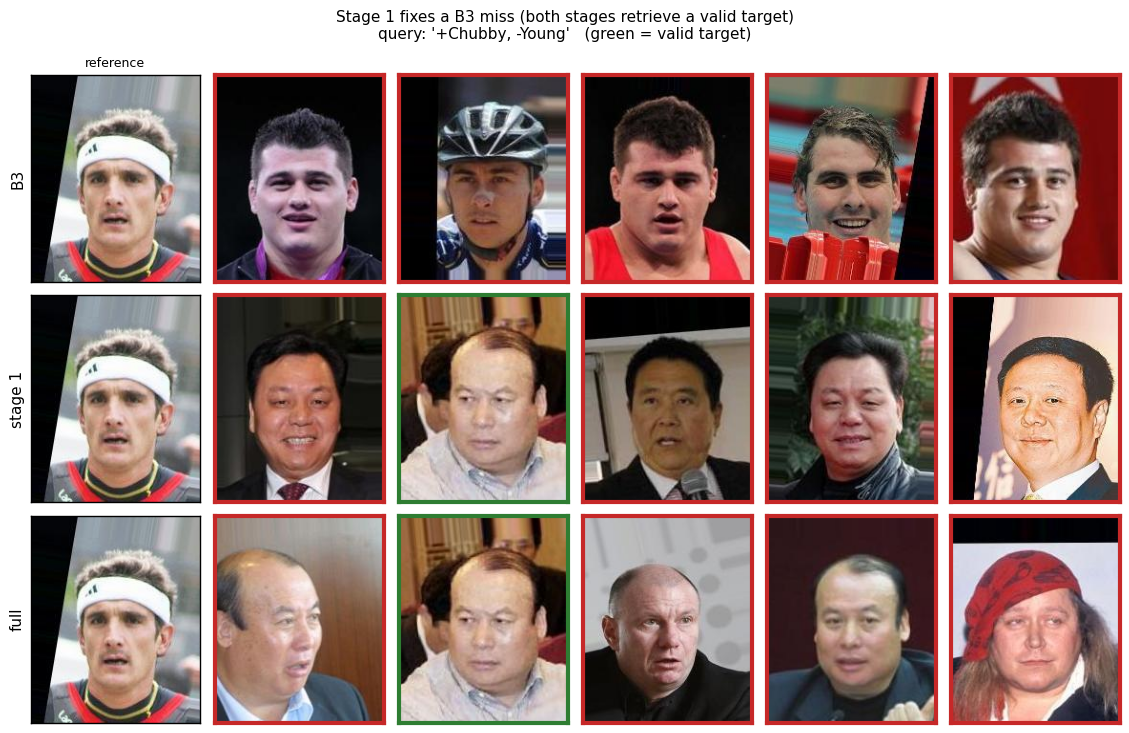

In [29]:
def find_entry(*signed_attrs):
    want = set(signed_attrs)
    for i, e in enumerate(bench_test):
        got = {(int(s), ATTR_NAMES[c]) for s, c in parse_query(e["query"])}
        if got == want:
            return i
    raise KeyError(signed_attrs)


def pick_source(entry_i, b3_hit, stage1_hit, full_hit, K=5):
    '''First source with the requested (B3, stage1, full) hit pattern at
    top-K (else first source of the entry).'''
    m = (res_b3[entry_i]["hits"][K] == b3_hit) \
        & (res_ours[entry_i]["hits"][K] == stage1_hit) \
        & (res_stack[entry_i]["hits"][K] == full_hit)
    src_ids = np.array([int(k) for k in bench_test[entry_i]["ground_truth"]])
    cand = src_ids[m]
    return int(cand[0]) if len(cand) else int(src_ids[0])


def top_k_cos(query_fn, entry, src, k=5):
    q = query_fn(V["test"][torch.tensor([src], device=DEV)],
                 parse_query(entry["query"]))
    scores = (q @ V["test"].T)[0]
    scores[src] = -torch.inf
    return scores.topk(k).indices.cpu().numpy()


def top_k_stack(entry, src, k=5):
    '''Full system: stage-1 top-200 re-ranked by the full predicate.'''
    conds = parse_query(entry["query"])
    ccols = [c for _, c in conds]
    rest = [c for c in range(40) if c not in ccols]
    csigns = torch.tensor([s for s, _ in conds], device=DEV) > 0
    idx = torch.tensor([src], device=DEV)
    sc = stage1_fn(V["test"][idx], conds) @ V["test"].T
    sc[0, src] = -torch.inf
    top = sc.topk(M_TOP, dim=1).indices
    p_cand = P_MLP_TEST[top]
    pc = p_cand[:, :, ccols]
    lg_con = torch.log(torch.where(csigns.view(1, 1, -1), pc, 1 - pc)).sum(-1)
    p_r = p_cand[:, :, rest]
    pref = P_MLP_TEST[idx][:, None, rest]
    score = lg_con + pb_tail_le2(p_r * pref + (1 - p_r) * (1 - pref)) \
        + 1e-4 * sc.gather(1, top)
    order = score[0].topk(k).indices
    return top[0][order].cpu().numpy()


def show_case(entry_i, src, title, k=5):
    entry = bench_test[entry_i]
    gt = set(entry["ground_truth"][str(src)])
    rankers = [("B3", lambda e, s: top_k_cos(make_b3(A_STAR, B_STAR), e, s, k)),
               ("stage 1", lambda e, s: top_k_cos(query_fn_from(model_final),
                                                  e, s, k)),
               ("full", lambda e, s: top_k_stack(e, s, k))]
    fig, axes = plt.subplots(len(rankers), k + 1,
                             figsize=(1.9 * (k + 1), 2.5 * len(rankers)))
    for r, (name, fn) in enumerate(rankers):
        idxs = [src] + fn(entry, src).tolist()
        for c, idx in enumerate(idxs):
            ax = axes[r, c]
            ax.imshow(Image.open(IMG_DIR / test_filenames[idx]))
            ax.set_xticks([])
            ax.set_yticks([])
            if c == 0:
                ax.set_ylabel(name, fontsize=11)
                edge, w = "black", 1
            else:
                edge, w = ("#2e7d32", 3) if idx in gt else ("#c62828", 3)
            for sp in ax.spines.values():
                sp.set_color(edge)
                sp.set_linewidth(w)
    axes[0, 0].set_title("reference", fontsize=9)
    fig.suptitle(f"{title}\nquery: '{entry['query']}'   "
                 f"(green = valid target)", fontsize=11)
    plt.tight_layout()
    plt.show()


i_success = find_entry((1, "Chubby"), (-1, "Young"))
show_case(i_success, pick_source(i_success, b3_hit=0, stage1_hit=1,
                                 full_hit=1),
          "Stage 1 fixes a B3 miss (both stages retrieve a valid target)")

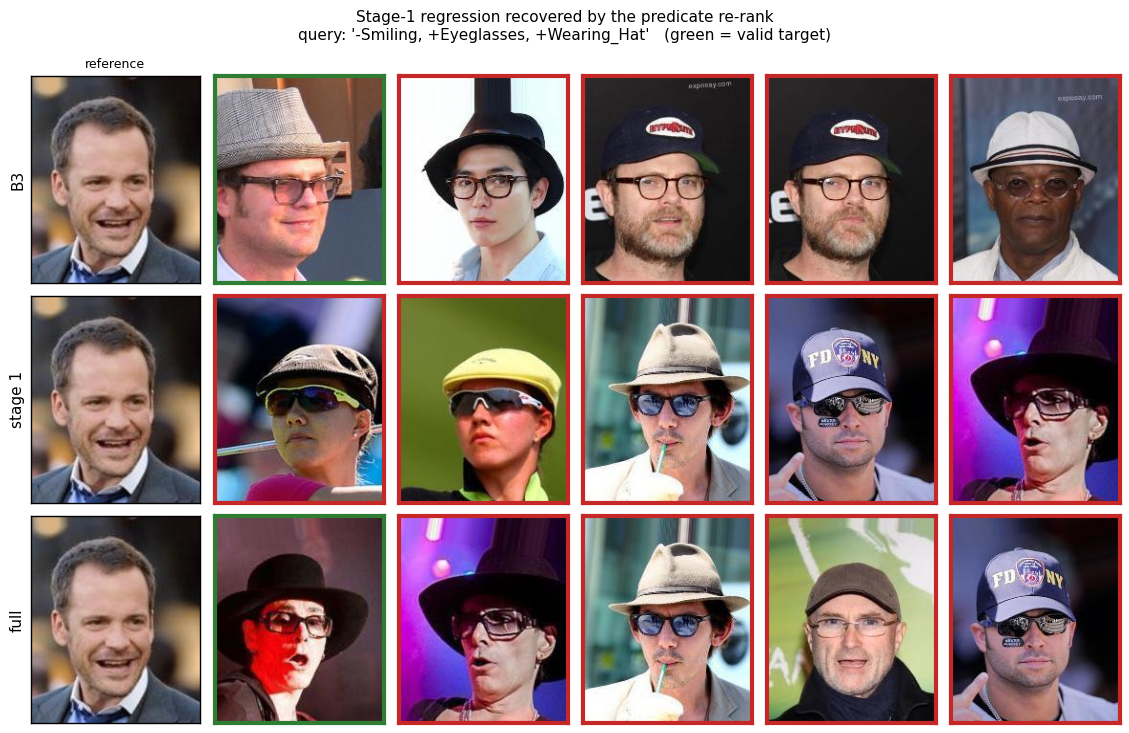

In [30]:
i_regr = find_entry((-1, "Smiling"), (1, "Eyeglasses"), (1, "Wearing_Hat"))
show_case(i_regr, pick_source(i_regr, b3_hit=1, stage1_hit=0, full_hit=1),
          "Stage-1 regression recovered by the predicate re-rank")

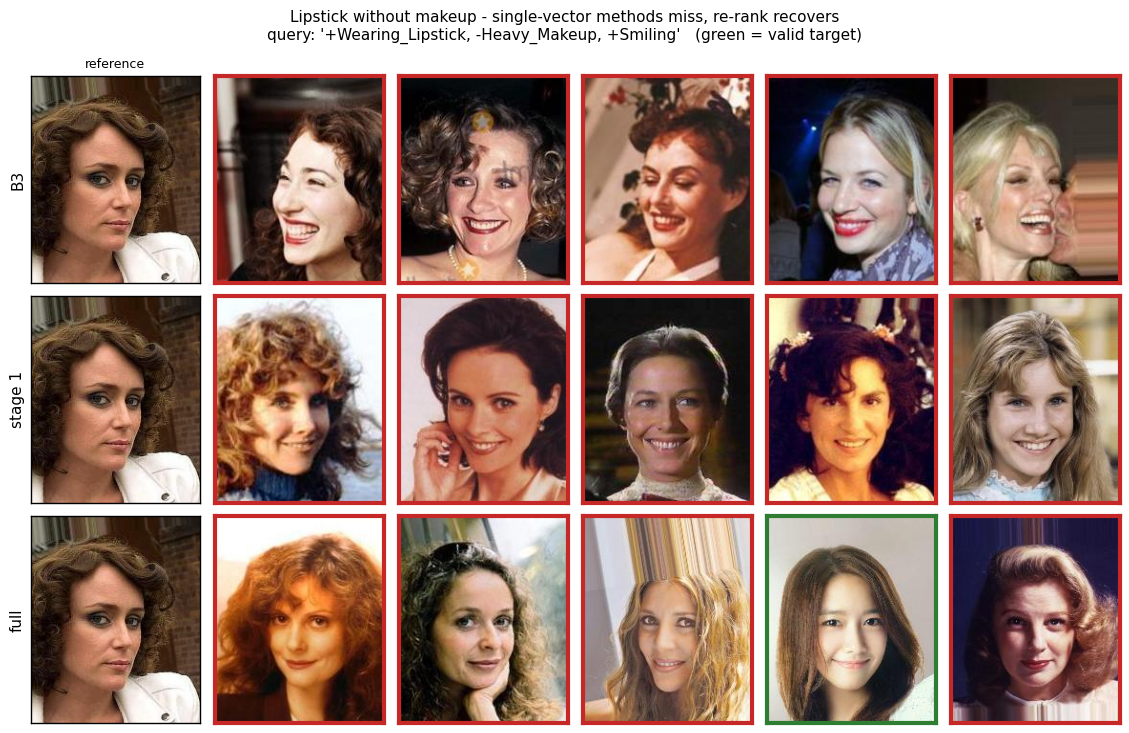

In [31]:
i_fail = find_entry((1, "Wearing_Lipstick"), (-1, "Heavy_Makeup"),
                    (1, "Smiling"))
show_case(i_fail, pick_source(i_fail, b3_hit=0, stage1_hit=0, full_hit=1),
          "Lipstick without makeup - single-vector methods miss, "
          "re-rank recovers")

Reading the three cases along the columns B3 → stage 1 → full. In the
**first** case the stage-1 directions already compose the two edits without
destroying identity, where B3's static steps over- or under-shoot one
attribute; the re-rank keeps the win. The **hat triple** is the stage-1
regression from Section 11: the learned edit lands in a region *visually*
compatible with the words (headwear plus eyewear, no smile) but wrong for
the benchmark — sunglasses and sports caps rather than the annotated
`Eyeglasses`/`Wearing_Hat` looks — yet a valid target still sits inside its
top-200, and the predicate re-rank surfaces it, recovering past B3's level.
The **lipstick triple** is the most instructive. Asking for lipstick
*without* heavy makeup is rare in the database and nearly self-contradictory
in CLIP space, because lipstick and makeup are strongly entangled (lipstick
*is* makeup): B3 retrieves smiling faces with lipstick *and* heavy makeup
(the $+d_{lipstick}$ push drags makeup along), while stage 1 — whose negative
makeup direction is one of the least symmetric in Section 12.1 — overcorrects
toward clean faces that lose the lipstick. No point on the linear segment
between the two edits satisfies both constraints, which is why every
single-vector method scores near zero here. The re-rank sidesteps the
entanglement entirely: it never edits a vector, it *reads* each candidate's
attributes with independent probes and scores the conjunction directly, so a
face that genuinely has lipstick and low makeup wins even though no additive
query embedding could point at it. This is the qualitative signature of the
whole design — when the target manifold is not a linear translate of the
reference, verification succeeds where vector arithmetic cannot. Its residual
limit is the probes: where two attributes are so entangled that the probes
themselves correlate, the conjunction is only partially recoverable, which is
why this query improves markedly but does not fully solve.

## 13 . Discussion and limitations

**Why the two stages are complementary.** They attack the two halves of the
relevance predicate with the tool each half needs. Stage 1 re-estimates the
*edit vectors themselves* under the benchmark's success criterion: the
zero-shot text deltas point roughly right but carry the text-image modality
gap, and contrastive training against benchmark-consistent positives and
identity/condition/hard negatives corrects each direction's aim and length
jointly — including learning that negated attributes need their own
directions (Section 12.1). But a single query vector, however well aimed, ranks
by one dot product, and the preservation half of the predicate (Hamming
$\le 2$ on ~37 unqueried attributes) is an order statistic no linear
functional can represent — which is exactly what the Section 9 oracle
decomposition isolated. Stage 2 scores that predicate directly, as a
probabilistic conjunction with an error budget, over the identity-plausible
candidates stage 1 already surfaced. The division of labour is visible in the
numbers: stage 1 lifts B3 by +0.096, stage 2 lifts stage 1 by +0.236, and the
second jump is larger precisely because it addresses the half that had never
been scored.

This reframes the CLAY line of work twice over. The four falsifications
(H1–H4) and the gating ablation say *dynamic, per-reference* conditioning is
not where the headroom lives — before making multi-condition composition
dynamic, make the per-condition representations sign-aware and
retrieval-supervised. And the stage-1/stage-2 split says the composition and
the *verification* of a compositional query are different problems: fusing
conditions into one embedding is the right tool for a first pass over 20k
images, but the final ranking wants the predicate evaluated on each
candidate, not baked into a vector.

**Limitations.**

* Single frozen backbone (ViT-B/32) and a single dataset; CelebA attribute
  annotations are noisy and partly subjective, which bounds any
  attribute-defined benchmark from above.
* Stage 2 is a re-ranker: its ceiling is stage-1 coverage (cov@$M$), so
  first-pass recall ultimately caps the system. Because the joint score keeps
  rising with $M$ on the mirror (Section 10), our fixed $M = 200$ leaves real
  headroom on the table — the reported test number is, if anything,
  conservative in this respect — but widening $M$ costs compute per query and
  we did not spend the test budget re-selecting it.
* The remaining gap to that ceiling is *probe-limited*, and unequally: where
  two attributes are entangled enough that their probes correlate (lipstick /
  heavy makeup), the conjunction is only partially recoverable, which is why
  that query improves sharply but does not close.
* The bootstrap CIs quantify source-sampling uncertainty only; every
  component uses one seed and a fixed budget, so training-seed variance is
  not measured.
* The gating result (no reliable gain) is partly *structural to this benchmark* (sources
  violate all constraints by construction); on a benchmark whose references
  may partially satisfy the conditions, gating could still matter.



## 14 . Conclusion

Starting from the assignment's naive latent arithmetic, we (1) verified the
benchmark pipeline exactly, (2) measured a ten-method training-free ladder,
falsifying four natural design hypotheses, (3) trained a 40k-parameter fusion
module — per-(attribute, sign) directions initialized at the strongest
baseline and supervised with benchmark-consistent contrastive queries — that
improves the official test benchmark from 0.208 to 0.303, and showed via an
initialization-controlled ablation that reference-conditioned gating gives no
reliable gain here, (4) decomposed the residual error with label oracles to show
the single-vector stage is scoring-limited, not candidate-limited, and (5)
added a second stage that scores the benchmark predicate exactly — a
Poisson-binomial tail over calibrated per-attribute posteriors — lifting test
macro R@10 to **0.540** (bootstrap 95% CI on each declared step), with gains
on all 14 entries. Two portable insights: in CLIP space *removing* an
attribute is not the opposite of *adding* it; and a compositional query is
better *verified* on candidates than *baked* into a single embedding — the
composition and the ranking want different representations.

## References

<!-- changed: corrected title to match the assignment's reference list -->
* Sohwi Lim, Lee Hyoseok, Jungjoon Park, and Tae-Hyun Oh. *Clay: Conditional
  visual similarity modulation in vision-language embedding space.* CVPR, 2026.
<!-- changed: corrected title (GDE is the method name, not the paper title) -->
* Davide Berasi, Matteo Farina, Massimiliano Mancini, Elisa Ricci, and Nicola
  Strisciuglio. *Not only text: Exploring compositionality of visual
  representations in vision-language models.* CVPR, 2025.
* Radford et al., *Learning Transferable Visual Models From Natural Language
  Supervision (CLIP)*, ICML 2021.
* Liu et al., *Deep Learning Face Attributes in the Wild (CelebA)*,
  ICCV 2015.
* van den Oord, Li, Vinyals, *Representation Learning with Contrastive
  Predictive Coding*, arXiv:1807.03748, 2018.
* Hong, *On computing the distribution function for the Poisson binomial
  distribution*, Computational Statistics & Data Analysis, 2013.

---

**Reproducibility notes.** Seeds are fixed (`SEED = 0`) for sampling,
training and the bootstrap; heavy artifacts (CLIP embeddings, model
checkpoints) are cached to persistent storage and re-created automatically if
absent. All reported numbers are produced by the cells above, executed top to
bottom on a GPU runtime; minor last-digit drift across GPU generations is
possible (fp16 autocast during extraction, non-deterministic reduction
order). The full negative-results ladder re-tunes itself only when
`RUN_EXTENDED = True`.


## 15. Appendix: Interpretability with Sparse Autoencoder

This section is an appendix to address structural phenomena that we never observed directly:
* Negation is not the opposite of addition (Section 12.1)
* Lipstick and heavy makeup are entangled (Section 12.2)
* Per-query difficulty varies far more than the macro averages suggest (Section 11.1)

This appendix tests that structure by training a Sparse Autoencoder on the cached CLIP features and naming its neurons against an open vocabulary. This method follows Zaigrajew et al., *Interpreting CLIP with Hierarchical Sparse Autoencoders* (ICML 2025) for the architecture and protocol, and Rao et al. (2024) for the naming step.

Three gates were used before any cell was run:
* **Gate 1:** Reconstruction cosine $\ge 0.90$
* **Gate 2:** Concept coverage $\ge 25/40$
* **Gate 3:** Dead-neuron fraction $< 0.30$

In [32]:
SAE_SEED = 0
N_LATENT = 1024
K_ACTIVE = 32
SAE_STEPS = 20000                       
RECON_MIN = 0.90 
DEAD_MAX = 0.30   
class TopKSAE(nn.Module):
    '''
    Sparse autoencoder with a hard TopK constraint.
    Decomposes a 512-d CLIP embedding into 1024 concepts, of which only 32 may
    be active per image. That budget of 32 is what forces each concept to mean ONE thing.
    '''
    def __init__(self, n_input=512, n_latent=N_LATENT, k=K_ACTIVE):
        super().__init__()
        self.n_input = n_input
        self.n_latent = n_latent
        self.k = k
        self.b_pre = nn.Parameter(torch.zeros(n_input)) 
        self.b_enc = nn.Parameter(torch.zeros(n_latent))
        w = torch.empty(n_latent, n_input)
        nn.init.kaiming_uniform_(w, a=5 ** 0.5)
        self.W_enc = nn.Parameter(w.clone())
        self.W_dec = nn.Parameter(w.clone())
        # Normalization
        with torch.no_grad():
            self.W_dec.data = F.normalize(self.W_dec.data, dim=1)
    def normalize_decoder(self):
        '''
        Lock every row of W_dec to unit length.
        This will prewvent model to cheat
        '''
        with torch.no_grad():
            self.W_dec.data = F.normalize(self.W_dec.data, dim=1)

    def encode(self, x):
        pre = (x - self.b_pre) @ self.W_enc.T + self.b_enc # 512 to 1024
        vals, idx = pre.topk(self.k, dim=-1)
        z = torch.zeros_like(pre)
        z.scatter_(-1, idx, F.relu(vals)) # Put value back to original position
        return z
    def decode(self, z): # Back to original dimension
        return z @ self.W_dec + self.b_pre
    def forward(self, x):
        z = self.encode(x)
        return self.decode(z), z

def sae_gates(model, x_val, batch=8192):
    '''
    Evaluate gates 1 and 3 on data never seen during training.
    Chunked at 8192 because 19,867 faces x 1024 slots at once would exhaust
    GPU memory.
    '''
    cos_sum = 0.0 
    l0_sum = 0.0
    n = 0
    active = torch.zeros(model.n_latent, dtype=torch.bool, device=x_val.device)
    with torch.no_grad():
        for lo in range(0, len(x_val), batch):
            xb = x_val[lo:lo + batch]
            x_hat, z = model(xb) # Embedding Reconstruction
            cos_sum += F.cosine_similarity(xb, x_hat, dim=1).sum().item() # Cosine similarity of vector
            active |= (z != 0).any(dim=0) # Does slot active
            l0_sum += (z != 0).sum(dim=1).float().sum().item() # How many active slot each image
            n += len(xb)
    return {"recon_cos": cos_sum / n,
            "dead_frac": 1.0 - active.float().mean().item(),
            "l0": l0_sum / n}

Three gates declared before training:
- Gate1: Reconstuction cosine $\ge 0.90$ on the held-out: if 32 active slots cannot rebuild the embedding, whatever the encoded result is, it is not what the retrieval system ranks by.
- Gate2: Concep coverage $\ge 25$ of 40 attributes: if the benchmark's own attributes have no slot, the dictionary is not about faces.
- Gate3: Dead neuron fraction $< 0.30$:slots that are never active inflate apparent capacity without contributing, and Zaigrajew et al. treat anything above 1% as a failed run.

NOTE: *Mean $L_0$ is reported alongside as a mechanical check that the TopK
constraint binds — it is not a gate.*

In [33]:
SAE_SEED = 0
N_LATENT = 1024
K_ACTIVE = 32
SAE_STEPS = 20000
RECON_MIN = 0.90 # gate 1 threshold
DEAD_MAX = 0.30 # gate 3 threshold

torch.manual_seed(SAE_SEED)
X_TR, X_VA = V['train'], V['val']
sae = TopKSAE().to(DEV)
opt_sae = torch.optim.Adam(sae.parameters(), lr=1e-3)
gen_sae = torch.Generator().manual_seed(SAE_SEED)

t0 = time.time()
for step in range(1, SAE_STEPS + 1):
    idx = torch.randint(0, len(X_TR), (4096,), generator=gen_sae).to(DEV)
    xb = X_TR[idx]
    x_hat, _ = sae(xb)
    loss = ((xb - x_hat) ** 2).sum(dim=1).mean()
    opt_sae.zero_grad()
    loss.backward()
    opt_sae.step()
    sae.normalize_decoder()  
    if step % 4000 == 0 or step == 1:
        print(f'step {step:6d}  loss {loss.item():.4f}  '
              f'({(time.time() - t0) / 60:.1f} min)', flush=True)

SAE_GATES = sae_gates(sae, X_VA)
g1 = 'PASS' if SAE_GATES['recon_cos'] >= RECON_MIN else 'FAIL'
g3 = 'PASS' if SAE_GATES['dead_frac'] < DEAD_MAX else 'FAIL'

print(f'Gate 1 {"reconstruction cos":<22}{SAE_GATES["recon_cos"]:>8.4f}'
      f'[need >= {RECON_MIN:.2f}] {g1}')
print(f'Gate 3 {"dead neuron fraction":<22}{SAE_GATES["dead_frac"]:>8.4f}'
      f'[need < {DEAD_MAX:.2f}] {g3}')
print(f'{"mean L0 per input":<22}{SAE_GATES["l0"]:>8.1f} [k = {K_ACTIVE}]')

step      1  loss 0.7789  (0.0 min)
step   4000  loss 0.0574  (0.6 min)
step   8000  loss 0.0537  (1.3 min)
step  12000  loss 0.0531  (1.9 min)
step  16000  loss 0.0519  (2.6 min)
step  20000  loss 0.0515  (3.2 min)
Gate 1 reconstruction cos      0.9722[need >= 0.90] PASS
Gate 3 dead neuron fraction    0.2939[need < 0.30] PASS
mean L0 per input         32.0 [k = 32]


The autoencoder is **usable but only just.** 
<br>
Reconstruction cosine on the held-outdata is 0.9722 which is above 0.90 threshold. 
Dead neuron fraction is 0.2939 this almost reach the threshold of 0.30. Eventhough the experiment is almost perfect but the result is fragile.
The number of average active neuron Mean $L_0$ is 32 confiriming the ReLU applied after the TopK selection and never clipped a selected coordinate meaning we dont need to add penalty because of the sparsity is already in teh model.

<br>
Zaigrajew et al. treat a
dead fraction above 1% as a failed run meanwhile our model at 29% we are two orders of magnitude outisde their threshold. This happen cause the lack of training data CelebA 162k trainihng data meanwhile CC3M is ~3M, our expansion **also against their method 8-32x**. Our sparsity is also stricter than theirs: 32 active of 1024 is 96.9% zeros, against the ~80% the paper reports. A reconstruction below their 0.99 is therefore the expected cost of a stricter sparsity point on a backbone they never evaluate (ViT-B/32, 512-d), not a weaker model.

Major differences approach:
Our method use held-out instead of training set. Where our held-out only contains 19k held-out data compare to 163k training data. Thus affecting how many neurons to be fire.

In [34]:
import urllib.request

# STOP: is a common english function words it keep neuron from being named into 'the' or any other common english words.
STOP = set(('the of and to a in is it you that he was for on are as with his they at be this '
            'have from or one had by but not what all were we when your can said there use an '
            'each which she do how their if will up other about out many then them these so '
            'some her would make like him into time has two more very who its did get may than '
            'been new now way').split())
TEMPLATE_WORDS = {'photo', 'person', 'people', 'image', 'picture', 'someone'}
VOCAB_URL = ('https://raw.githubusercontent.com/first20hours/google-10000-english/'
             'master/google-10000-english-no-swears.txt')
raw = urllib.request.urlopen(VOCAB_URL, timeout=30).read().decode().split()
layer_a = [w for w in (t.strip().lower() for t in raw)
           if w.isalpha() and len(w) >= 3 and w not in STOP][:10000]

face_words = set()
for pos, neg in PROMPTS.values():       
    for tok in (pos + ' ' + neg).lower().replace(',', ' ').replace('.', ' ').split():
        tok = ''.join(ch for ch in tok if ch.isalpha())
        if len(tok) >= 3 and tok not in STOP and tok not in TEMPLATE_WORDS:
            face_words.add(tok)

layer_b = sorted(face_words - set(layer_a))
VOCAB = layer_a + layer_b
print(f'vocabulary: {len(layer_a)} layer-A + {len(layer_b)} layer-B = {len(VOCAB)}')


def embed_words(words, template, batch=512):
    '''CLIP text embeddings for a word list under one template, L2-normalized.'''
    out = []
    for lo in range(0, len(words), batch):
        chunk = [template.format(w=w) for w in words[lo:lo + batch]]
        out.append(F.normalize(text_features(chunk), dim=1))
    return torch.cat(out)


W_ROWS = F.normalize(sae.W_dec.detach(), dim=1)  
LIVE = torch.zeros(sae.n_latent, dtype=torch.bool, device=DEV) # Masking
with torch.no_grad():
    for lo in range(0, len(X_VA), 8192):
        LIVE |= (sae.encode(X_VA[lo:lo + 8192]) != 0).any(dim=0)
print(f'live neurons: {int(LIVE.sum())} of {sae.n_latent}')

TEMPLATES = ('{w}', 
             'a photo of a {w}',
             'a photo of a person {w}', 
             'a photo of a person with {w}')

best_template, best_median, T_VOCAB = None, -1.0, None
for tmpl in TEMPLATES:
    T = embed_words(VOCAB, tmpl)
    med = (W_ROWS[LIVE] @ T.T).max(dim=1).values.median().item()
    print(f'  template {tmpl!r:32s} median best cos = {med:.4f}')
    if med > best_median:
        best_template, best_median, T_VOCAB = tmpl, med, T
print(f'chosen template: {best_template!r}')

top_vals, top_idx = [t.cpu() for t in (W_ROWS @ T_VOCAB.T).topk(5, dim=1)]
NEURON_NAMES = {j: {'names': [VOCAB[i] for i in top_idx[j].tolist()],
                    'best_cos': round(top_vals[j, 0].item(), 4)}
                for j in LIVE.nonzero().flatten().tolist()}   # naming a dead slot is fiction
named = sum(v['best_cos'] >= 0.30 for v in NEURON_NAMES.values())
print(f'named at cos >= 0.30: {named} of {len(NEURON_NAMES)} live neurons')

T_ATTR = F.normalize(text_features([PROMPTS[a][0] for a in ATTR_NAMES]), dim=1)
attr_scores = T_ATTR @ W_ROWS.T
attr_scores[:, ~LIVE] = -1.0  # dead slots ineligible for argmax
attr_cos, attr_slot = attr_scores.max(dim=1)

n_cov = int((attr_cos >= 0.30).sum())
g2 = 'PASS' if n_cov >= 25 else 'FAIL'
cov = f'{n_cov}/40'
print(f'\nGate 2  {"concept coverage":<22}{cov:>8s} [need >= 25]   {g2}')

print(f'\n{"attribute":18s} {"neuron":>7s} {"cos":>7s}   top concepts')
for a in sorted(BENCH_ATTRS):
    i = ATTR_NAMES.index(a)
    j = int(attr_slot[i])
    print(f'{a:18s} {j:7d} {attr_cos[i].item():7.3f} {NEURON_NAMES[j]["names"][:4]}')

vocabulary: 9413 layer-A + 29 layer-B = 9442
live neurons: 723 of 1024
  template '{w}'                            median best cos = 0.0999
  template 'a photo of a {w}'               median best cos = 0.0960
  template 'a photo of a person {w}'        median best cos = 0.0830
  template 'a photo of a person with {w}'   median best cos = 0.0850
chosen template: '{w}'
named at cos >= 0.30: 10 of 723 live neurons

Gate 2  concept coverage          0/40 [need >= 25]   FAIL

attribute           neuron     cos   top concepts
Black_Hair             302   0.188 ['habitat', 'largest', 'interior', 'female']
Blond_Hair             178   0.195 ['blond', 'blonde', 'creek', 'shakira']
Chubby                 382   0.203 ['obesity', 'fat', 'chubby', 'rolls']
Eyeglasses             438   0.215 ['glasses', 'eyeglasses', 'specs', 'geek']
Heavy_Makeup           168   0.134 ['makeup', 'eye', 'cosmetics', 'evanescence']
Male                   302   0.144 ['habitat', 'largest', 'interior', 'female']
Mustach

We tried to assign a name to each decoder by finding the closest word from a 9.4k vocabulary. At a glance, the naming results make sense. For example:
attribute           neuron     cos   top concepts
- Eyeglasses             438   0.215   ['glasses', 'eyeglasses', 'specs', 'geek']
- Wearing_Lipstick       188   0.220   ['lipstick', 'rouge', 'red', 'lips']
- Wearing_Hat            284   0.291   ['hats', 'hat', 'fitted', 'inspector']

But the cosine score is low (0.13 to 0.29), meaning no attributes passed. This shows the concept label is correct, but the statistical similarity is low. We can see attributes like Heavy_Makeup are able to label themselves as 'makeup', 'eye', and 'cosmetics', but the score is only 0.134.

This result showed us the modality gap in CLIP, where the representations of text and images are not perfectly aligned. Thus, the cosine score between text and image is always low. This moved us to change the passing threshold to be higher than P95 (top 5%) from 1000 random words.

In [35]:
attr_phrases = [a.replace('_', ' ').lower() for a in ATTR_NAMES]
T_ATTR_BARE = F.normalize(text_features(attr_phrases), dim=1)

g_null = torch.Generator().manual_seed(SAE_SEED)
null_words = [VOCAB[i] for i in torch.randperm(len(VOCAB), generator=g_null)[:1000].tolist()]
T_NULL = embed_words(null_words, '{w}') 

live_cols = W_ROWS[LIVE] 
live_ids = LIVE.nonzero().flatten()
null_best = (T_NULL @ live_cols.T).max(dim=1).values
attr_best, attr_j = (T_ATTR_BARE @ live_cols.T).max(dim=1)
NULL_P95 = torch.quantile(null_best, 0.95).item() 
print(f'null over 1000 random words:  median {null_best.median().item():.4f}'
      f' | p95 {NULL_P95:.4f} | max {null_best.max().item():.4f}')

n_cov2 = int((attr_best > NULL_P95).sum())
g2p = 'PASS' if n_cov2 >= 25 else 'FAIL'
perm, absol = f'{n_cov2}/40', f'{n_cov}/40'
print(f'\ngate 2  {"permutation coverage":<22}{perm:>8s}   [need >= 25]   {g2p}')
print(f'gate 2  {"absolute coverage":<22}{absol:>8s} [need >= 25] FAIL (as declared)')

print(f'\n{"":4s}{"attribute":18s} {"cos":>7s} {"x null":>8s} top concepts')
for a in sorted(BENCH_ATTRS):
    i = ATTR_NAMES.index(a)
    c = attr_best[i].item()
    jn = int(live_ids[attr_j[i]])
    mark = 'OK' if c > NULL_P95 else '--'
    print(f'{mark:4s}{a:18s} {c:7.3f} {c / NULL_P95:7.2f}x '
          f'{NEURON_NAMES[jn]["names"][:3]}')

null over 1000 random words:  median 0.0946 | p95 0.1680 | max 0.2340

gate 2  permutation coverage     12/40   [need >= 25]   FAIL
gate 2  absolute coverage         0/40 [need >= 25] FAIL (as declared)

    attribute              cos   x null top concepts
OK  Black_Hair           0.229    1.37x ['eminem', 'evanescence', 'offset']
OK  Blond_Hair           0.199    1.18x ['blond', 'blonde', 'creek']
--  Chubby               0.129    0.77x ['obesity', 'fat', 'chubby']
OK  Eyeglasses           0.326    1.94x ['glasses', 'eyeglasses', 'specs']
--  Heavy_Makeup         0.126    0.75x ['makeup', 'eye', 'cosmetics']
OK  Male                 0.209    1.24x ['habitat', 'largest', 'interior']
OK  Mustache             0.228    1.36x ['mustache', 'saddam', 'ron']
OK  Smiling              0.209    1.24x ['laugh', 'smiling', 'smile']
--  Wavy_Hair            0.120    0.71x ['curly', 'belarus', 'alberta']
OK  Wearing_Hat          0.303    1.80x ['hats', 'hat', 'fitted']
OK  Wearing_Lipstick     0.202

This method also gives a failed result, where at a P95 score of 0.168, only 12 out of 40 attributes pass (it needs $\ge 25$). With these experiments, we found out that the autoencoder finds the structure of the attributes, but not strongly enough. Twelve is not due to chance either: at $\alpha=0.05$ per attribute, chance alone predicts two, and twelve or more arises with a probability below $10^{-6}$.

We also found out that some attributes share the same neuron, 302. This can be marked as a residue of attributes that do not have their own path, which we will need to explore further. Examples of these attributes are: Black_Hair, Male, Young, Wavy_Hair.

The difficulty is not confined to the 40 attributes. The median live slot's best match over the whole vocabulary is 0.0999, below the null's P95 of 0.168, so most of the 723 live slots cannot be named at all. Naming the neurons therefore cannot be certified in this setting, even where the labels look right.


In [36]:
assert 'D_img' in globals(), 'needs D_img from Sec. 7.1 -- run that cell with RUN_EXTENDED = True' # Safety net

N_SRC = 2000
g_h3 = torch.Generator().manual_seed(SAE_SEED)
v_src = X_TR[torch.randperm(len(X_TR), generator=g_h3)[:N_SRC].to(DEV)]


def concept_delta(D):
    '''Mean change in concept activation caused by each edit direction, (40, n_latent).'''
    with torch.no_grad():
        z0 = sae.encode(v_src)
        return torch.stack([(sae.encode(F.normalize(v_src + d, dim=1)) - z0).mean(0)
                            for d in D])


def overlap_matrix(D):
    '''Pairwise |cosine| between the concept effects of 40 edits; diagonal zeroed.'''
    U = F.normalize(concept_delta(D), dim=1)
    M = (U @ U.T).abs()
    M.fill_diagonal_(0.0) 
    return M


M_img, M_txt = overlap_matrix(D_img), overlap_matrix(D_sel)
n = len(M_img)
row_img, row_txt = M_img.sum(1) / (n - 1), M_txt.sum(1) / (n - 1)
o_img, o_txt = row_img.mean().item(), row_txt.mean().item()
verdict = 'SUPPORTED' if o_img > o_txt else 'NOT SUPPORTED'

print('concept-space overlap, mean over 40 attributes')
print(f'  {"image directions (B5)":<24}{o_img:>7.3f}')
print(f'  {"text directions (B3)":<24}{o_txt:>7.3f}')
print(f'  {"ratio":<24}{o_img / o_txt:>7.2f}x   -> H3 {verdict}')

dragged = M_img.argmax(dim=1)
print(f'\n{"attribute":18s} {"image":>8s} {"text":>8s}   most dragged (image)')
for a in sorted(BENCH_ATTRS):
    i = NAME2COL[a]
    j = int(dragged[i])
    print(f'{a:18s} {row_img[i]:8.3f} {row_txt[i]:8.3f}   {ATTR_NAMES[j]:18s} {M_img[i, j]:.3f}')

concept-space overlap, mean over 40 attributes
  image directions (B5)     0.363
  text directions (B3)      0.115
  ratio                      3.15x   -> H3 SUPPORTED

attribute             image     text   most dragged (image)
Black_Hair            0.235    0.120   Bushy_Eyebrows     0.609
Blond_Hair            0.389    0.102   Wearing_Necklace   0.827
Chubby                0.399    0.056   Double_Chin        0.983
Eyeglasses            0.385    0.101   Chubby             0.853
Heavy_Makeup          0.439    0.135   Wearing_Lipstick   0.994
Male                  0.401    0.079   Bags_Under_Eyes    0.966
Mustache              0.398    0.140   Goatee             0.984
Smiling               0.261    0.066   Mouth_Slightly_Open 0.886
Wavy_Hair             0.418    0.141   Wearing_Lipstick   0.902
Wearing_Hat           0.361    0.147   Goatee             0.732
Wearing_Lipstick      0.433    0.155   Heavy_Makeup       0.994
Young                 0.396    0.063   Attractive         0.918


In Section 7.1, image-space class-mean directions are rejected because even though the AUC score is good, the retrieval is bad. We suspect entanglement happens in this method. We tried to find proof without needing to name the neurons, by modifying the vector edit to 2000 embeddings sampled from the training split, and then calculating the overlapping active neurons.

The mean concept-space overlap over the 40 attributes is 0.363 for image
directions against 0.115 for text directions (3.15×), which supports H3.